## STADIOchoice Churn Prediction

### Objective and problem definition

Objective: Test whether subscriber/account information and behaviour available at a monthly index date can rank subscribers by the probability of a qualifying churn event in the following **30 days**.

The supplied data dictionary defines churn as subscriber-initiated cancellation without reactivation within 30 days, and the supplied `churn_indicator` is the authoritative outcome flag. A 30-day prediction horizon is therefore distinct from the 30-day reactivation rule.

Observation grain: One eligible subscriber per month-end index date. A subscriber may appear in multiple periods because the intended use is forecasting future behaviour for existing subscribers. Features use only records dated on or before the index date; the label uses the following 30 days. The final outcome table and final subscription status are never predictors.

### Environment Setup and Imports

In [2]:

from pathlib import Path
import sys
import platform
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve,
    brier_score_loss,
)
from sklearn.calibration import calibration_curve
from sklearn.base import clone



SEED = 42
HORIZON_DAYS = 30
LOOKBACK_DAYS = 90

CURRENT_DIR = Path.cwd().resolve()

possible_roots = [CURRENT_DIR, *CURRENT_DIR.parents]

PROJECT_ROOT = next(
    (
        root
        for root in possible_roots
        if (root / "data" / "stadiochoice").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project data directory.\n"
        f"Current working directory: {CURRENT_DIR}\n"
        "Expected: <project-root>/data/stadiochoice/"
    )

DATA_DIR = PROJECT_ROOT / "data" / "stadiochoice"

FILES = {
    "account": "2_subscriber_account.csv",
    "subscription": "3_subscription.csv",
    "viewing": "4_viewing_behaviour.csv",
    "engagement": "5_engagement_behaviour.csv",
    "content": "5b_content_reference.csv",
    "billing": "6_billing_payment_history.csv",
    "outcome": "7_cancellation_retention.csv",
}

print(
    f"Python: {platform.python_version()} | "
    f"pandas: {pd.__version__} | "
    f"NumPy: {np.__version__}"
)
print(f"Project root: {PROJECT_ROOT}")
print(f"Input directory: {DATA_DIR}")

missing_files = [
    filename
    for filename in FILES.values()
    if not (DATA_DIR / filename).is_file()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing files in {DATA_DIR}:\n"
        + "\n".join(missing_files)
    )

print(f"All {len(FILES)} required CSV files are present.")

Python: 3.13.7 | pandas: 3.0.5 | NumPy: 2.5.2
Project root: C:\Users\sltha\Documents\STADIO\CAP182\capstone-project
Input directory: C:\Users\sltha\Documents\STADIO\CAP182\capstone-project\data\stadiochoice
All 7 required CSV files are present.


### Data inventory and loading

The README describes seven operational tables and their intended grains. We load them without silently dropping records, parse timestamp fields explicitly, and compare actual shapes with the documented counts. The content lookup enriches viewing records, but the churn modelling table will be built at subscriber-month grain.

In [3]:
tables = {
    name: pd.read_csv(DATA_DIR / filename)
    for name, filename in FILES.items()
}

date_cols = {
    "account": [
        "account_creation_date",
        "acquisition_date",
    ],
    "subscription": [
        "subscription_start_date",
        "subscription_end_date",
    ],
    "viewing": [
        "viewing_timestamp",
    ],
    "engagement": [
        "event_timestamp",
    ],
    "billing": [
        "billing_date",
    ],
    "outcome": [
        "cancellation_date",
        "reactivation_date",
        "retention_interaction_date",
    ],
}

for table, columns in date_cols.items():
    for column in columns:
        tables[table][column] = pd.to_datetime(
            tables[table][column],
            errors="coerce",
        )


table_grains = {
    "account": "one row per subscriber",
    "subscription": "one row per subscription",
    "viewing": "one row per viewing session",
    "engagement": "one row per engagement event",
    "content": "one row per content item",
    "billing": "one row per billing event",
    "outcome": "one row per cancellation/retention event",
}

inventory = pd.DataFrame([
    {
        "table": name,
        "file": FILES[name],
        "rows": len(df),
        "columns": df.shape[1],
        "subscriber_ids": (
            df["subscriber_id"].nunique()
            if "subscriber_id" in df.columns
            else np.nan
        ),
        "grain_from_documentation": table_grains[name],
    }
    for name, df in tables.items()
])

display(inventory)


for name, df in tables.items():
    print(f"\n{name}: {df.shape}")

    summary = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_pct": (
            100 * df.isna().mean()
        ).round(2),
    })

    display(summary)


,table,file,rows,columns,subscriber_ids,grain_from_documentation
0,account,2_subscriber_account.csv,2110,8,2104.0,one row per subscriber
1,subscription,3_subscription.csv,2104,9,2104.0,one row per subscription
2,viewing,4_viewing_behaviour.csv,8939,11,2104.0,one row per viewing session
3,engagement,5_engagement_behaviour.csv,28118,7,2104.0,one row per engagement event
4,content,5b_content_reference.csv,880,3,NaN,one row per content item
5,billing,6_billing_payment_history.csv,32114,9,2104.0,one row per billing event
6,outcome,7_cancellation_retention.csv,539,11,539.0,one row per cancellation/retention event



account: (2110, 8)


,dtype,missing,missing_pct
subscriber_id,str,0,0.00
household_id,str,0,0.00
account_creation_date,datetime64[us],0,0.00
acquisition_date,datetime64[us],0,0.00
acquisition_channel,str,0,0.00
acquisition_campaign,str,278,13.18
customer_segment,str,0,0.00
province,str,85,4.03



subscription: (2104, 9)


,dtype,missing,missing_pct
subscriber_id,str,0,0.00
subscription_id,str,0,0.00
subscription_plan,str,0,0.00
subscription_start_date,datetime64[us],0,0.00
subscription_end_date,datetime64[us],1727,82.08
subscription_status,str,0,0.00
monthly_fee,float64,0,0.00
discount_amount,float64,0,0.00
promotion_code,str,966,45.91


...

,dtype,missing,missing_pct
content_id,str,0,0.0
title,str,0,0.0
category,str,0,0.0



billing: (32114, 9)


,dtype,missing,missing_pct
subscriber_id,str,0,0.0
billing_date,datetime64[us],0,0.0
amount_charged,float64,0,0.0
payment_status,str,0,0.0
payment_method,str,0,0.0
payment_failure_indicator,bool,0,0.0
payment_failure_count,int64,0,0.0
refund_indicator,bool,0,0.0
refund_amount,float64,0,0.0



outcome: (539, 11)


,dtype,missing,missing_pct
subscriber_id,str,0,0.00
cancellation_date,datetime64[us],0,0.00
cancellation_reason,str,0,0.00
cancellation_channel,str,0,0.00
churn_indicator,bool,0,0.00
reactivation_indicator,bool,0,0.00
reactivation_date,datetime64[us],497,92.21
retention_interaction_date,datetime64[us],134,24.86
retention_offer,str,134,24.86
offer_accepted,object,134,24.86


### Integrity and schema validation

We check the documented keys, duplicates, missing identifiers, date coverage, category cleanliness and basic numeric plausibility. A duplicate is reported first; the six duplicated account rows are exact row-for-row duplicates, so the modelling copy removes only exact duplicates (the raw table remains unchanged). Missing `province`, `promotion_code`, search fields and `subscription_end_date` have documented meanings and are not treated as generic errors.

#### Duplicate and key checks

In [7]:
key_map = {
    "account": ["subscriber_id"],
    "subscription": ["subscriber_id", "subscription_id"],
    "viewing": ["session_id"],
    "content": ["content_id"],
    "outcome": ["subscriber_id"],
}

quality_rows = []

for name, df in tables.items():
    key_columns = key_map.get(name, [])

    quality_rows.append({
        "Table": name,
        "Rows": len(df),
        "Duplicate Rows": int(df.duplicated().sum()),
        "Missing Subscriber IDs": (
            int(df["subscriber_id"].isna().sum())
            if "subscriber_id" in df.columns else np.nan
        ),
        "Key Columns": ", ".join(key_columns),
        "Duplicate Keys": (
            int(df.duplicated(key_columns).sum())
            if key_columns and all(c in df.columns for c in key_columns)
            else np.nan
        ),
    })

display(pd.DataFrame(quality_rows))

for name in ["account", "subscription", "outcome"]:
    print(
        f"{name.capitalize()} subscriber IDs unique: "
        f"{tables[name]['subscriber_id'].is_unique}"
    )

,Table,Rows,Duplicate Rows,Missing Subscriber IDs,Key Columns,Duplicate Keys
0,account,2110,6,0.0,subscriber_id,6.0
1,subscription,2104,0,0.0,"subscriber_id, subscription_id",0.0
2,viewing,8939,0,0.0,session_id,0.0
3,engagement,28118,3,0.0,,NaN
4,content,880,0,NaN,content_id,0.0
5,billing,32114,0,0.0,,NaN
6,outcome,539,0,0.0,subscriber_id,0.0


Account subscriber IDs unique: False
Subscription subscriber IDs unique: True
Outcome subscriber IDs unique: True


#### Data quality checks

In [9]:
date_quality = []

for name, columns in date_cols.items():
    df = tables[name]

    for column in columns:
        date_quality.append({
            "Table": name,
            "Column": column,
            "Parsed / Total": (
                f"{df[column].notna().sum(): } / {len(df): }"
            ),
            "Earliest Date": df[column].min(),
            "Latest Date": df[column].max(),
        })

display(pd.DataFrame(date_quality))

,Table,Column,Parsed / Total,Earliest Date,Latest Date
0,account,account_creation_date,2110 / 2110,2024-01-02 06:34:25,2026-05-20 22:15:38
1,account,acquisition_date,2110 / 2110,2024-01-02 09:39:03,2026-05-21 00:21:00
2,subscription,subscription_start_date,2104 / 2104,2024-01-02 09:39:03,2026-05-21 00:21:00
3,subscription,subscription_end_date,377 / 2104,2024-11-05 09:31:57,2026-06-30 23:59:59
4,viewing,viewing_timestamp,8939 / 8939,2024-01-14 15:01:13,2026-06-29 23:58:33
5,engagement,event_timestamp,28118 / 28118,2024-01-14 14:48:26,2026-06-29 23:57:48
6,billing,billing_date,32114 / 32114,2024-01-02 00:00:00,2026-06-30 00:00:00
7,outcome,cancellation_date,539 / 539,2024-10-31 09:31:57,2026-06-23 17:50:02
8,outcome,reactivation_date,42 / 539,2025-06-26 18:30:59,2026-06-30 10:16:51
9,outcome,retention_interaction_date,405 / 539,2024-10-27 14:38:09,2026-06-22 15:44:24


#### Referential integrity checks

In [10]:
viewing_content_ids = tables["viewing"]["content_id"]
reference_content_ids = tables["content"]["content_id"]

unmatched_content_ids = (
    ~viewing_content_ids.isin(reference_content_ids)
).sum()

print("Viewing content IDs without reference:", int(unmatched_content_ids))

account_ids = set(tables["account"]["subscriber_id"].dropna())

for name in ["subscription", "viewing", "engagement", "billing", "outcome"]:
    subscriber_ids = set(tables[name]["subscriber_id"].dropna())
    unmatched_ids = subscriber_ids - account_ids

    print(f"{name.capitalize()}: subscriber IDs not in account table = {len(unmatched_ids)}")

Viewing content IDs without reference: 0
Subscription: subscriber IDs not in account table = 0
Viewing: subscriber IDs not in account table = 0
Engagement: subscriber IDs not in account table = 0
Billing: subscriber IDs not in account table = 0
Outcome: subscriber IDs not in account table = 0


**Cleaning decisions.** The account table is the subscriber population anchor. `household_id` is not a unique key. The supplied dictionary says `payment_failure_count` is a repeated observation-period total, so it must not be summed across billing rows; this notebook excludes it from event aggregation and instead counts event-level failures from `payment_failure_indicator`. Category text is trimmed and normalised for consistent encoding, but raw source tables are retained unchanged.

In [11]:
# Create modelling copies with consistent whitespace/casing 
# for categorical fields only
CAT_COLS = {
    "account": [
        "acquisition_channel",
        "acquisition_campaign",
        "customer_segment",
        "province",
    ],
    "subscription": [
        "subscription_plan",
        "subscription_status",
        "promotion_code",
    ],
    "viewing": [
        "content_category",
        "device_type",
    ],
    "engagement": [
        "event_type",
    ],
    "billing": [
        "payment_status",
        "payment_method",
    ],
    "outcome": [
        "cancellation_reason",
        "cancellation_channel",
        "retention_offer",
        "offer_outcome",
    ],
}

# IDs and free-text search terms are preserved
# categorical fields are normalised below
for name, columns in CAT_COLS.items():
    df = tables[name]

    for column in columns:
        if column not in df.columns:
            continue

        values = (
            df[column]
            .astype("string")
            .str.strip()
            .str.replace(r"\s+", " ", regex=True)
            .str.title()
        )

        tables[name][column] = values.mask(
            values.eq(""),
            pd.NA,
        )

print("Categorical columns normalised.")

print(
    "Observed subscription statuses:",
    tables["subscription"]["subscription_status"]
    .value_counts(dropna=False)
    .to_dict(),
)

print(
    "Observed churn labels:",
    tables["outcome"]["churn_indicator"]
    .value_counts(dropna=False)
    .to_dict(),
)


Categorical columns normalised.
Observed subscription statuses: {'Active': 1675, 'Cancelled': 368, 'Suspended': 40, 'Lapsed': 12, 'Reactivated': 9}
Observed churn labels: {True: 368, False: 171}


### Target definition and eligibility

The official label is `churn_indicator` in the cancellation/retention table. We do not reconstruct the 30-day reactivation rule from incomplete assumptions; we validate the supplied flag against the documented cancellation and reactivation fields, then use it as authoritative.

For each month-end index date, an account is eligible if it was acquired by that date and has no recorded cancellation on or before that date. A positive label means a qualifying churn event occurs in `(index date, index date + 30 days]`. An eligible subscriber with no qualifying event in that window is negative. Index dates stop at **31 May 2026** so the 30-day outcome window is covered by the extract ending 30 June 2026. This is a forward-looking event label, not classification of an already-cancelled account.

In [12]:
account = tables["account"].copy().drop_duplicates()  # Repeated rows are exact duplicates.
subscription = tables["subscription"].copy()
outcome = tables["outcome"].copy()

# Validate the supplied target against the key edge-case fields in the dictionary
print(
    "Outcome rows:", len(outcome),
    "| unique subscribers:", outcome["subscriber_id"].nunique()
)

print("Target by reactivation flag:")
display(
    pd.crosstab(
        outcome["reactivation_indicator"],
        outcome["churn_indicator"],
        dropna=False,
    )
)

print("Target by offer outcome:")
display(
    pd.crosstab(
        outcome["offer_outcome"],
        outcome["churn_indicator"],
        dropna=False,
    )
)

observation_start = pd.Timestamp("2024-01-01")
observation_end = pd.Timestamp("2026-06-30 23:59:59")

outside_window = (
    (outcome["cancellation_date"] < observation_start)
    | (outcome["cancellation_date"] > observation_end)
)

print(
    "Cancellation dates outside documented observation window:",
    int(outside_window.sum()),
)

# Fail visibly if the supplied target contradicts explicit dictionary edge cases
contradictions = outcome[
    outcome["offer_outcome"].isin(["Paused", "Retained", "Downgraded"])
    & outcome["churn_indicator"].eq(True)
]

print(
    "Contradictions with non-churn offer outcomes requiring review:",
    len(contradictions),
)

if len(contradictions):
    display(contradictions.head(10))

# The extract describes 1:1 account-subscription relationships but contains six unmatched accounts
account_ids = set(account["subscriber_id"])
subscription_ids = set(subscription["subscriber_id"])

print(
    "Accounts without subscription row:",
    len(account_ids - subscription_ids),
)

print(
    "Subscription rows without account:",
    len(subscription_ids - account_ids),
)

# Parse and validate key timestamps
# Account creation/acquisition may be same-day but should not be after index
for df, column in [
    (account, "acquisition_date"),
    (account, "account_creation_date"),
    (subscription, "subscription_start_date"),
]:
    print(
        column,
        "missing:",
        int(df[column].isna().sum()),
    )

Outcome rows: 539 | unique subscribers: 539
Target by reactivation flag:


churn_indicator,False,True
reactivation_indicator,,
False,162,335
True,9,33


Target by offer outcome:


churn_indicator,False,True
offer_outcome,,
Churned,0,335
Downgraded,36,0
Paused,23,0
Reactivated Later,9,33
Retained,103,0


Cancellation dates outside documented observation window: 0
Contradictions with non-churn offer outcomes requiring review: 0
Accounts without subscription row: 0
Subscription rows without account: 0
acquisition_date missing: 0
account_creation_date missing: 0
subscription_start_date missing: 0


### Experimental design and chronological partitions

Monthly snapshots let the model learn from earlier periods and be evaluated on later periods. The intended scenario is future behaviour of existing subscribers, so the same subscriber can legitimately appear in multiple time partitions; this is not a new-subscriber generalisation test. We report subscriber overlap and treat repeated observations as a limitation when interpreting uncertainty.

Partitions follow the supplied reference periods where possible: training through September 2025, validation October 2025 to January 2026, and test February–May 2026. The last period is possible because the chosen 30-day horizon ends by June 2026. Splits are by **index date**, never random row splitting.

In [13]:
INDEX_DATES = pd.date_range('2024-04-30','2026-05-31',freq='ME')
print('Index dates:', len(INDEX_DATES), '| first:', INDEX_DATES.min().date(), '| last:', INDEX_DATES.max().date())
print('Training index dates: through 2025-09-30; validation: 2025-10-31 to 2026-01-31; test: 2026-02-28 to 2026-05-31.')

Index dates: 26 | first: 2024-04-30 | last: 2026-05-31
Training index dates: through 2025-09-30; validation: 2025-10-31 to 2026-01-31; test: 2026-02-28 to 2026-05-31.


### Focused exploratory analysis

Inspect the target event distribution and the available activity coverage. Event counts are not subscriber counts and this distinction matters because high-activity subscribers generate many rows.

In [14]:
VISUALISATION_DIR = Path.cwd().resolve() / "visualisations"
VISUALISATION_DIR.mkdir(parents=True, exist_ok=True)

print(f"Visualisations directory: {VISUALISATION_DIR}")

Visualisations directory: C:\Users\sltha\Documents\STADIO\CAP182\capstone-project\notebooks\visualisations


#### Recorded Cancellation Outcomes

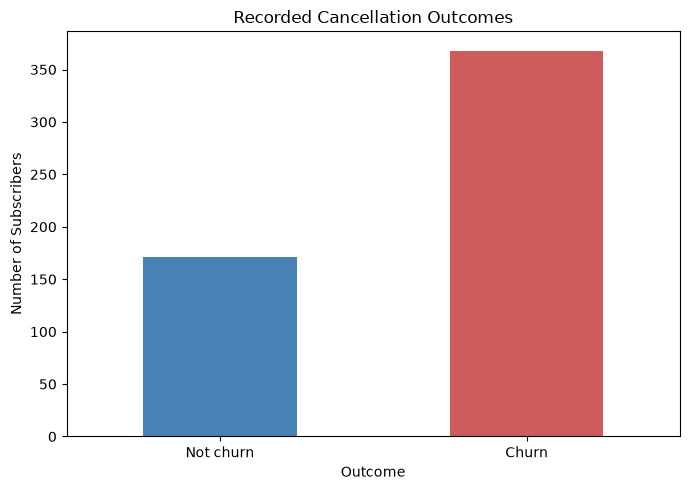

In [15]:
churn_counts = (
    outcome["churn_indicator"]
    .value_counts()
    .sort_index()
    .rename(index={False: "Not churn", True: "Churn"})
)

fig, ax = plt.subplots(figsize=(7, 5))

churn_counts.plot(kind="bar", ax=ax, color=["steelblue", "indianred"])

ax.set_title("Recorded Cancellation Outcomes")
ax.set_xlabel("Outcome")
ax.set_ylabel("Number of Subscribers")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
fig.savefig(
    VISUALISATION_DIR / "recorded_cancellation_outcomes.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

#### Timestamped Source-record Coverage

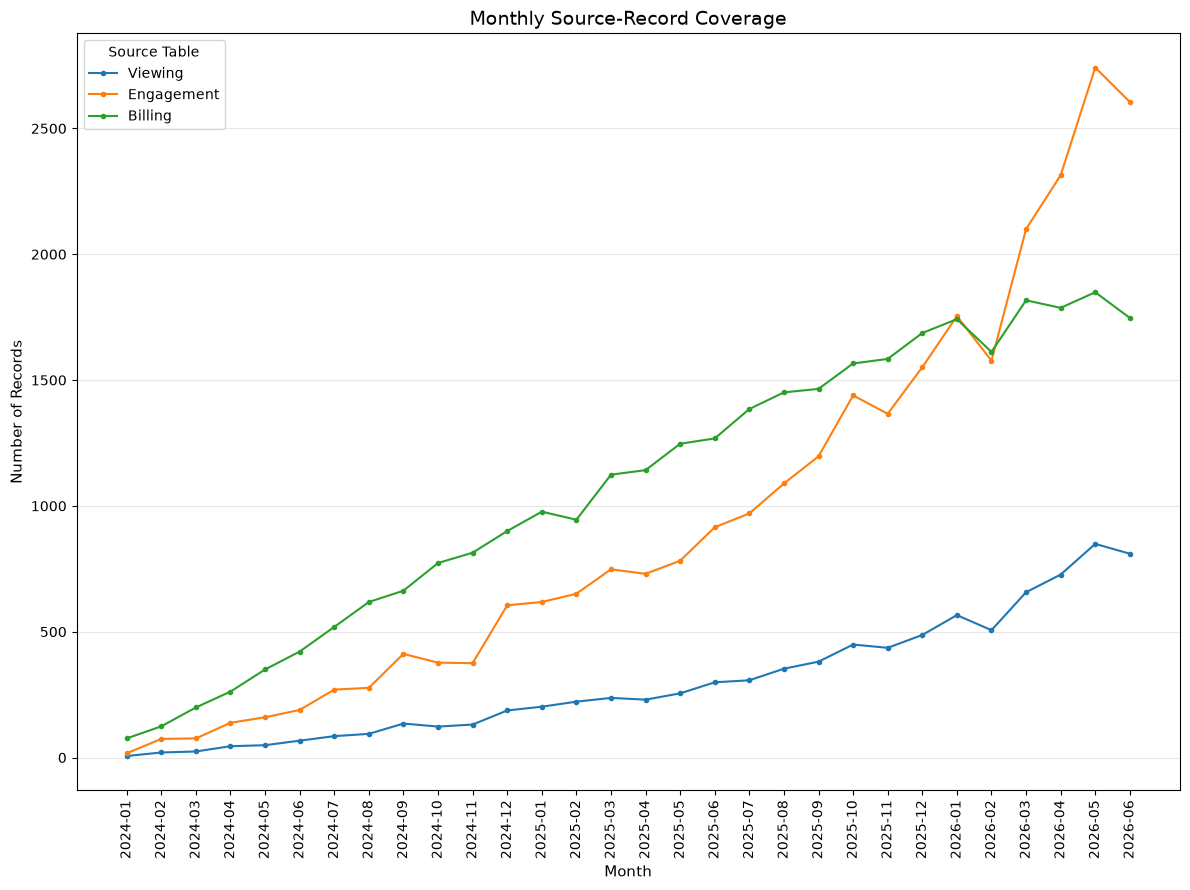

In [17]:
date_columns = {
    "Viewing": ("viewing", "viewing_timestamp"),
    "Engagement": ("engagement", "event_timestamp"),
    "Billing": ("billing", "billing_date"),
}

fig, ax = plt.subplots(figsize=(12, 9))

for label, (table_name, column) in date_columns.items():
    dates = tables[table_name][column].dropna()

    monthly_counts = (
        dates.dt.to_period("M")
        .value_counts()
        .sort_index()
    )

    ax.plot(
        monthly_counts.index.astype(str),
        monthly_counts.to_numpy(dtype=float),
        marker="o",
        markersize=3,
        label=label,
    )

ax.set_title("Monthly Source-Record Coverage", fontsize=14)
ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Number of Records", fontsize=11)
ax.tick_params(axis="x", rotation=90)
ax.legend(title="Source Table")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

fig.savefig(
    VISUALISATION_DIR / "monthly_source_record_coverage.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

#### Churn Prevalence

In [18]:
print(
    "Recorded churn prevalence:",
    f"{outcome['churn_indicator'].mean():.1%}",
)

print(
    "Note: This is the prevalence among cancellation-table rows, "
    "not the overall subscriber population, because retained "
    "subscribers without cancellation rows are absent from this table."
)

print(f"Plots saved to: {VISUALISATION_DIR}")

Recorded churn prevalence: 68.3%
Note: This is the prevalence among cancellation-table rows, not the overall subscriber population, because retained subscribers without cancellation rows are absent from this table.
Plots saved to: C:\Users\sltha\Documents\STADIO\CAP182\capstone-project\notebooks\visualisations


### Feature Engineering

Build one row per eligible subscriber and index date. Static acquisition/account attributes are combined with counts and summaries from the **previous 90 days**, ending at the index date. All behavioural and billing filters are applied before aggregation. No cancellation reason, retention interaction, final subscription status, subscription end date, or future record is used as a predictor.

Feature groups: subscriber/account attributes; 90-day viewing activity; 90-day engagement activity; and 90-day billing/payment behaviour. Absence of viewing records is kept distinct from a numeric zero where possible using an event-presence indicator.

In [19]:
# Event tables are sorted once; per-snapshot 
# filtering uses timestamp boundaries
view = tables["viewing"].copy()
eng = tables["engagement"].copy()
bill = tables["billing"].copy()

view["viewing_timestamp"] = pd.to_datetime(
    view["viewing_timestamp"],
    errors="coerce",
)

eng["event_timestamp"] = pd.to_datetime(
    eng["event_timestamp"],
    errors="coerce",
)

eng["content_click_indicator"] = (
    eng["content_click_indicator"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({"true": 1.0, "false": 0.0})
)

bill["billing_date"] = pd.to_datetime(
    bill["billing_date"],
    errors="coerce",
)


# Only use cancellation events to establish pre-index 
# eligibility and future labels
outcome_events = (
    outcome[
        [
            "subscriber_id",
            "cancellation_date",
            "churn_indicator",
            "reactivation_date",
            "offer_outcome",
        ]
    ]
    .dropna(subset=["subscriber_id", "cancellation_date"])
    .copy()
)

outcome_events["cancellation_date"] = pd.to_datetime(
    outcome_events["cancellation_date"],
    errors="coerce",
)

outcome_events["reactivation_date"] = pd.to_datetime(
    outcome_events["reactivation_date"],
    errors="coerce",
)


# Account attributes available at acquisition
# Omit household and subscriber identifiers as model predictors
static_cols = [
    "subscriber_id",
    "account_creation_date",
    "acquisition_date",
    "acquisition_channel",
    "acquisition_campaign",
    "customer_segment",
    "province",
]

static = account[static_cols].copy()

static["account_creation_date"] = pd.to_datetime(
    static["account_creation_date"],
    errors="coerce",
)

static["acquisition_date"] = pd.to_datetime(
    static["acquisition_date"],
    errors="coerce",
)


# Use subscription start date only to calculate tenure
# Plan, fee, discount, end date and status lack 
# effective-dated history and are excluded
sub_static = subscription[
    ["subscriber_id", "subscription_start_date"]
].copy()

sub_static["subscription_start_date"] = pd.to_datetime(
    sub_static["subscription_start_date"],
    errors="coerce",
)

static = static.merge(
    sub_static,
    on="subscriber_id",
    how="left",
    validate="one_to_one",
)


rows = []

for idx in INDEX_DATES:
    end = idx + pd.Timedelta(days=HORIZON_DAYS)

    eligible = static[
        static["acquisition_date"].notna()
        & (static["acquisition_date"] <= idx)
    ].copy()

    past = outcome_events[
        outcome_events["cancellation_date"] <= idx
    ]

    # Only a true churn or a non-churn cancellation 
    # still awaiting reactivation makes the subscriber ineligible
    permanent_churn = set(
        past.loc[
            past["churn_indicator"].eq(True),
            "subscriber_id",
        ]
    )

    awaiting_reactivation = past[
        past["offer_outcome"].eq("Reactivated Later")
        & (
            past["reactivation_date"].isna()
            | (past["reactivation_date"] > idx)
        )
    ]

    ineligible_ids = (
        permanent_churn
        | set(awaiting_reactivation["subscriber_id"])
    )

    eligible = eligible[
        ~eligible["subscriber_id"].isin(ineligible_ids)
    ]

    # Only a subscription known to have started by the index date can contribute its plan/fee fields
    # Plan, fee and discount are excluded because no effective-dated history establishes their values at the index date
    eligible["index_date"] = idx

    eligible["account_age_days"] = (
        (idx - eligible["account_creation_date"])
        .dt.total_seconds()
        / 86400
    )

    eligible["subscriber_tenure_days"] = (
        (idx - eligible["acquisition_date"])
        .dt.total_seconds()
        / 86400
    )

    eligible["subscription_age_days"] = (
        (idx - eligible["subscription_start_date"])
        .dt.total_seconds()
        / 86400
    )

    lo = idx - pd.Timedelta(days=LOOKBACK_DAYS)

    # Viewing behaviour in the 90-day lookback window
    v = view[
        (view["viewing_timestamp"] > lo)
        & (view["viewing_timestamp"] <= idx)
    ]

    vagg = (
        v.groupby("subscriber_id")
        .agg(
            view_sessions_90d=("session_id", "nunique"),
            viewing_seconds_90d=("viewing_duration", "sum"),
            mean_completion_90d=("completion_rate", "mean"),
            mean_pause_count_90d=("pause_count", "mean"),
            abandonment_rate_90d=("abandonment_indicator", "mean"),
            last_viewing_timestamp=("viewing_timestamp", "max"),
        )
        .reset_index()
    )

    vagg["days_since_last_viewing"] = (
        (idx - vagg["last_viewing_timestamp"])
        .dt.total_seconds()
        / 86400
    )

    vagg = vagg.drop(columns="last_viewing_timestamp")

    # Engagement behaviour in the 90-day lookback window
    e = eng[
        (eng["event_timestamp"] > lo)
        & (eng["event_timestamp"] <= idx)
    ]

    eagg = (
        e.groupby("subscriber_id")
        .agg(
            engagement_events_90d=("event_type", "size"),
            distinct_event_types_90d=("event_type", "nunique"),
            search_events_90d=(
                "event_type",
                lambda s: s.eq("Search").sum(),
            ),
            content_click_rate_90d=(
                "content_click_indicator",
                "mean",
            ),
            scroll_count_90d=("scroll_count", "sum"),
            last_engagement_timestamp=("event_timestamp", "max"),
        )
        .reset_index()
    )

    eagg["days_since_last_engagement"] = (
        (idx - eagg["last_engagement_timestamp"])
        .dt.total_seconds()
        / 86400
    )

    eagg = eagg.drop(columns="last_engagement_timestamp")

    # Billing behaviour in the 90-day lookback window
    b = bill[
        (bill["billing_date"] > lo)
        & (bill["billing_date"] <= idx)
    ]

    bagg = (
        b.groupby("subscriber_id")
        .agg(
            billing_events_90d=("billing_date", "size"),
            amount_charged_90d=("amount_charged", "sum"),
            failed_payment_events_90d=(
                "payment_failure_indicator",
                "sum",
            ),
            refunds_90d=("refund_indicator", "sum"),
            refund_amount_90d=("refund_amount", "sum"),
            mean_charge_90d=("amount_charged", "mean"),
            last_billing_date=("billing_date", "max"),
        )
        .reset_index()
    )

    bagg["days_since_last_billing"] = (
        (idx - bagg["last_billing_date"])
        .dt.total_seconds()
        / 86400
    )

    bagg = bagg.drop(columns="last_billing_date")

    # Combine account attributes and lookback 
    # features into one snapshot
    snap = (
        eligible
        .merge(
            vagg,
            on="subscriber_id",
            how="left",
            validate="one_to_one",
        )
        .merge(
            eagg,
            on="subscriber_id",
            how="left",
            validate="one_to_one",
        )
        .merge(
            bagg,
            on="subscriber_id",
            how="left",
            validate="one_to_one",
        )
    )

    # Label only from qualifying churn records occurring 
    # after index and within the prediction horizon
    future = outcome_events[
        (outcome_events["cancellation_date"] > idx)
        & (outcome_events["cancellation_date"] <= end)
        & (outcome_events["churn_indicator"] == True)
    ]

    positive_ids = set(future["subscriber_id"])

    snap["target_churn_30d"] = (
        snap["subscriber_id"]
        .isin(positive_ids)
        .astype("int8")
    )

    snap["label_window_end"] = end

    rows.append(snap)


panel = pd.concat(rows, ignore_index=True)


# Explicit missingness indicators distinguish no observed events 
# in a lookback window from zero activity
for column in [
    "view_sessions_90d",
    "engagement_events_90d",
    "billing_events_90d",
]:
    observed_column = column.replace(
        "_90d",
        "_observed_90d",
    )

    panel[observed_column] = (
        panel[column].notna().astype("int8")
    )


print(
    "Panel shape:", panel.shape,
    "| subscribers:", panel["subscriber_id"].nunique(),
    "| index dates:", panel["index_date"].nunique(),
)

print(
    "Target counts:",
    panel["target_churn_30d"].value_counts().to_dict(),
    "| prevalence:",
    round(panel["target_churn_30d"].mean(), 4),
)

display(
    panel.groupby("index_date")
    .agg(
        rows=("subscriber_id", "size"),
        positive=("target_churn_30d", "sum"),
        prevalence=("target_churn_30d", "mean"),
    )
    .tail(8)
)

Panel shape: (29252, 36) | subscribers: 2103 | index dates: 26
Target counts: {0: 28884, 1: 368} | prevalence: 0.0126


,rows,positive,prevalence
index_date,,,
2025-10-31,1503,22,0.014637
2025-11-30,1563,28,0.017914
2025-12-31,1611,24,0.014898
2026-01-31,1665,46,0.027628
2026-02-28,1687,35,0.020747
2026-03-31,1731,47,0.027152
2026-04-30,1744,47,0.026950
2026-05-31,1755,21,0.011966


### Feature dictionary (selected engineered fields)

| Feature | Calculation | Grain / period | Leakage note |
|---|---|---|---|
| `account_age_days` | index date − account creation date | subscriber-month; age at index | Uses only dates known by index |
| `subscriber_tenure_days` | index date − acquisition date | subscriber-month; age at index | Uses only dates known by index |
| `subscription_age_days` | index date − subscription start date | subscriber-month; age at index | Blank if subscription has not started |
| `view_sessions_90d` | distinct session IDs in prior 90 days | subscriber-month | No future viewing records |
| `viewing_seconds_90d` | sum of viewing duration in prior 90 days | seconds / subscriber-month | No future viewing records |
| `mean_completion_90d` | mean recorded completion proportion in prior 90 days | proportion / subscriber-month | Live-sport measurement caveat applies |
| `days_since_last_viewing` | index date − latest prior viewing timestamp | days / subscriber-month | Missing when no recorded viewing |
| `engagement_events_90d` | event rows in prior 90 days | count / subscriber-month | No future engagement records |
| `search_events_90d` | count of `Search` events in prior 90 days | count / subscriber-month | Query text excluded |
| `failed_payment_events_90d` | sum of event-level failure indicators in prior 90 days | count / subscriber-month | Does not sum repeated period-total field |
| `amount_charged_90d` | sum of charges in prior 90 days | ZAR / subscriber-month | Only prior billing records |
| `days_since_last_billing` | index date − latest prior billing date | days / subscriber-month | Missing when no prior billing record |

The final feature list is generated below from actual columns. The content lookup is validated, but title-level text is not used: free-text titles and search terms add complexity without a clear need for this capstone model.

### Feature checks and focused visualisation

Check for aggregation preserved at one row per subscriber per index date, whether labels have both classes by partition, and whether engineered values violate obvious constraints. Completion rates above one are not automatically removed because the dictionary warns that live-sport values may slightly exceed one.

Unique subscriber-index keys: True
Negative tenure values: 0
Negative durations/charges: {'viewing_seconds_90d': 0, 'amount_charged_90d': 0, 'refund_amount_90d': 0}


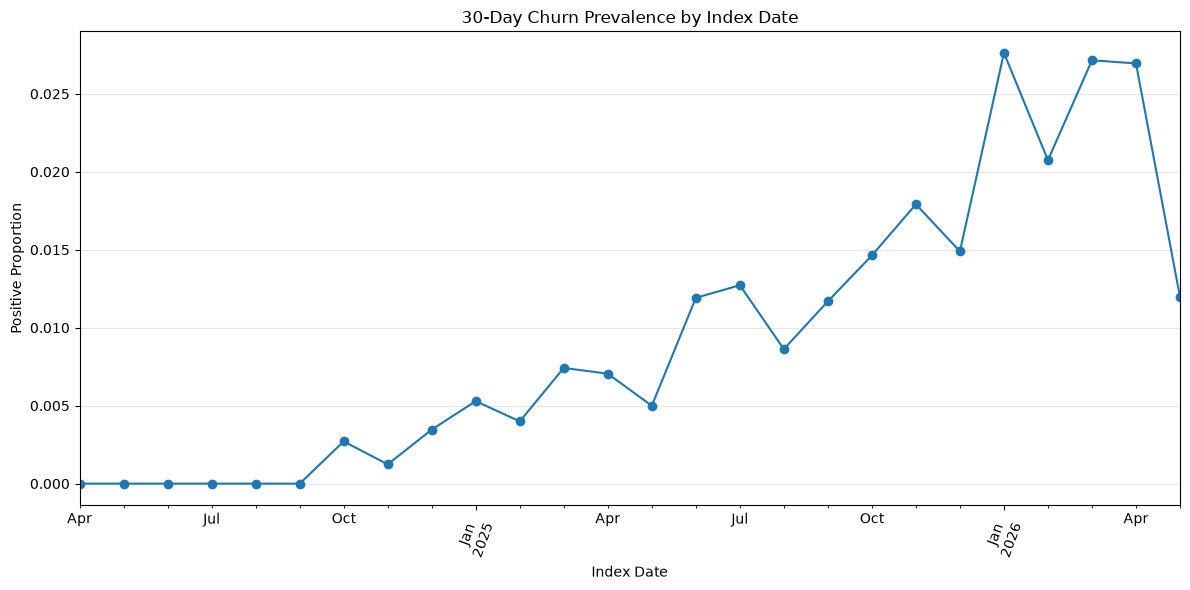

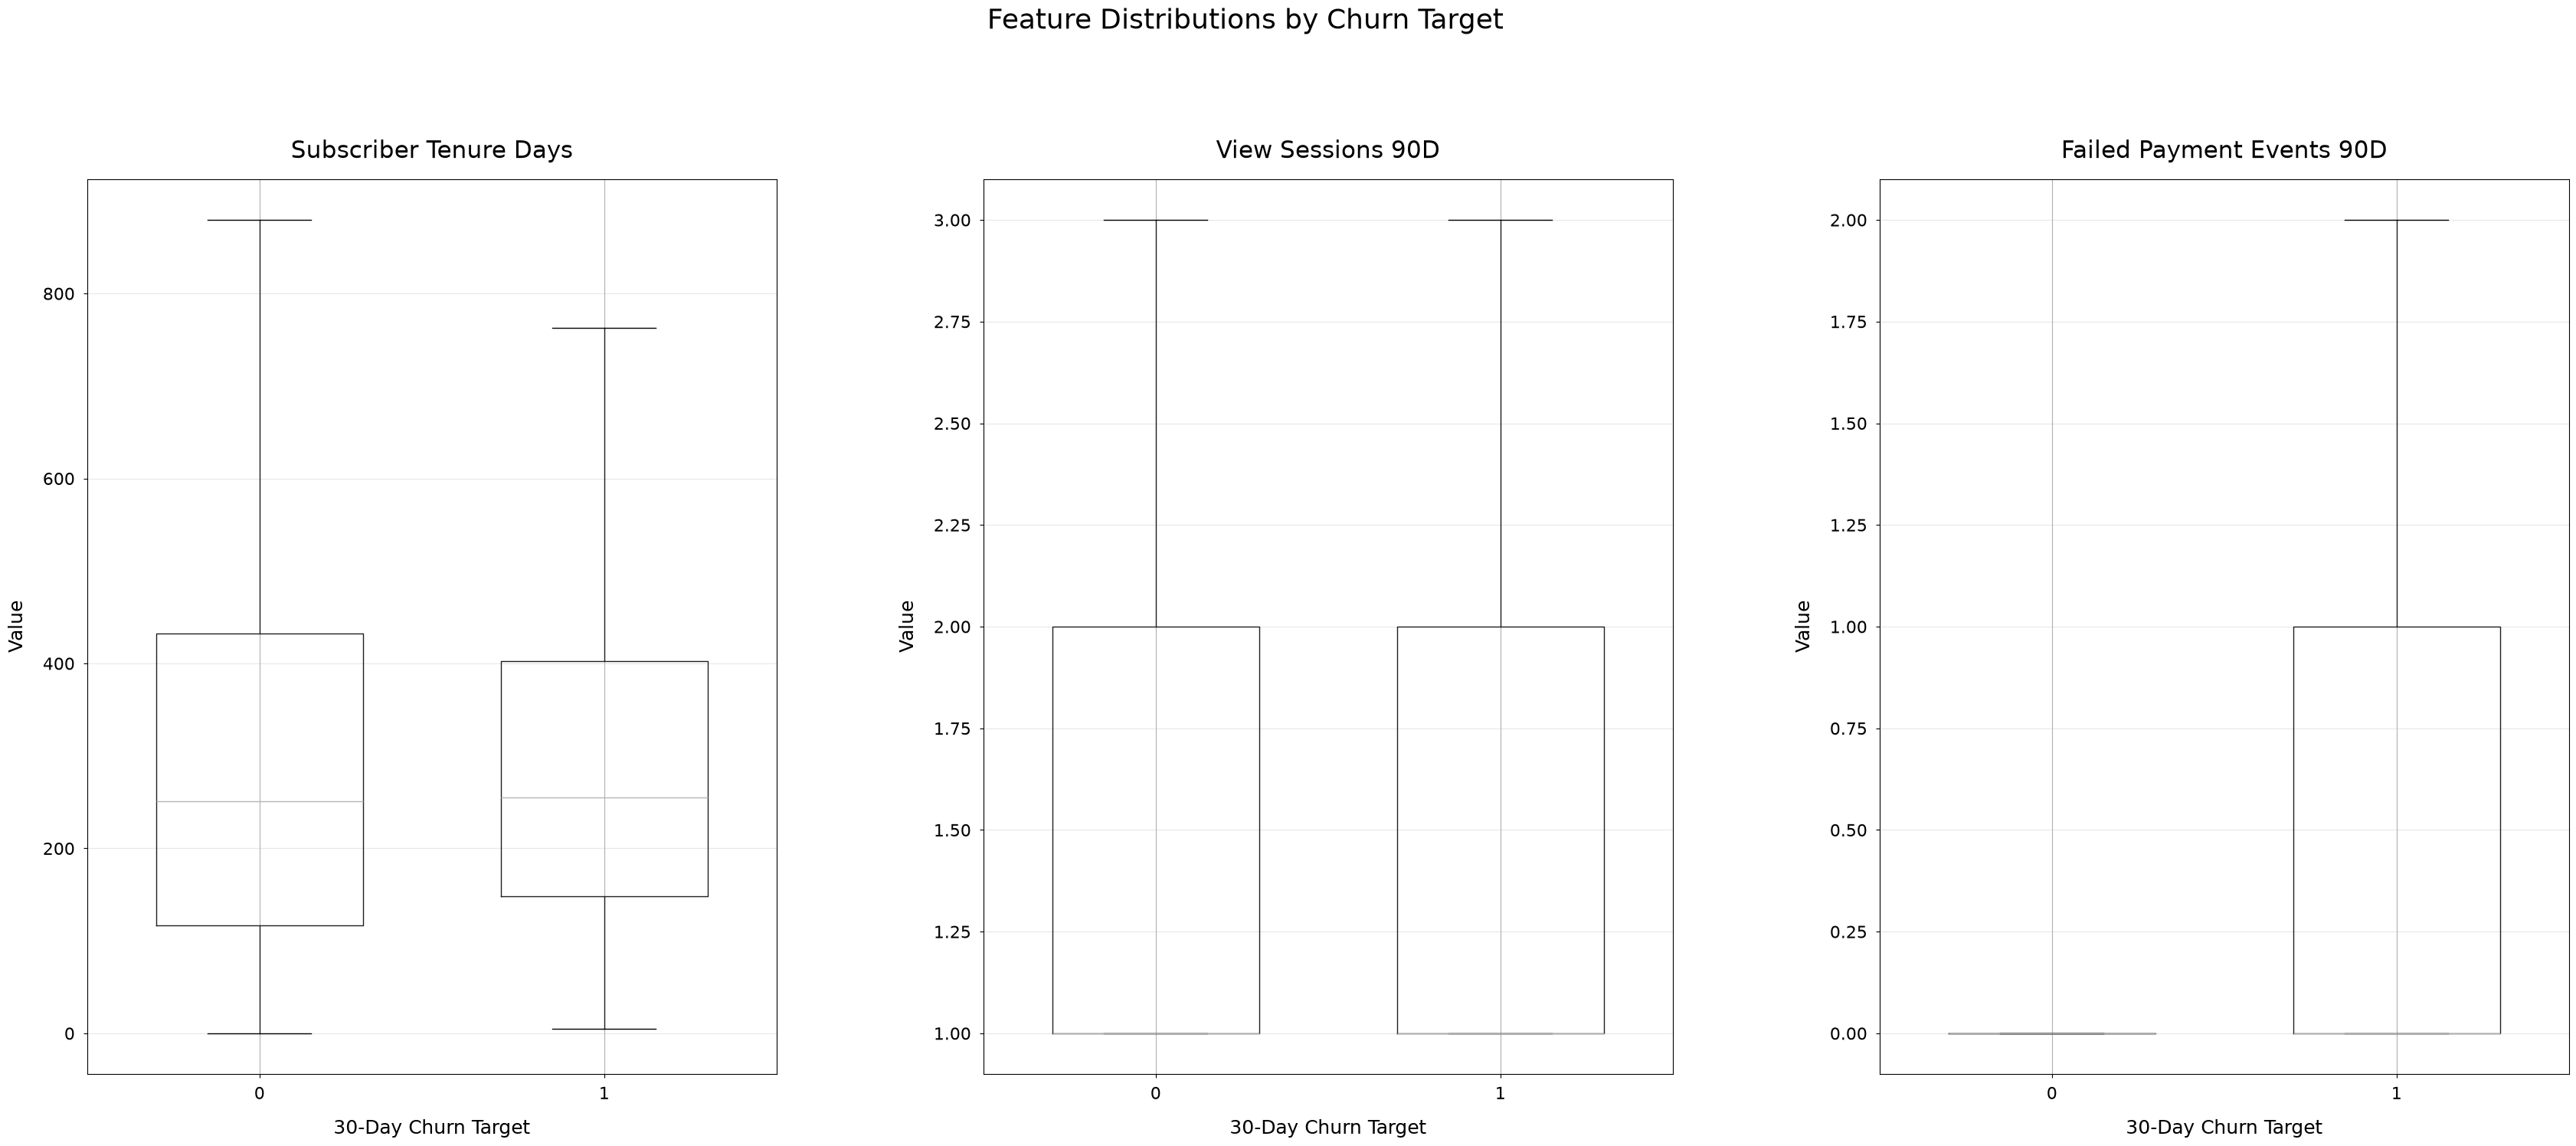

Plots saved to: C:\Users\sltha\Documents\STADIO\CAP182\capstone-project\notebooks\visualisations


In [23]:
assert not panel.duplicated(
    ["subscriber_id", "index_date"]
).any(), "Panel grain is not unique."

print(
    "Unique subscriber-index keys:",
    not panel.duplicated(["subscriber_id", "index_date"]).any(),
)

tenure_columns = [
    "account_age_days",
    "subscriber_tenure_days",
    "subscription_age_days",
]

print(
    "Negative tenure values:",
    int((panel[tenure_columns] < 0).sum().sum()),
)

charge_columns = [
    "viewing_seconds_90d",
    "amount_charged_90d",
    "refund_amount_90d",
]

print(
    "Negative durations/charges:",
    {
        column: int((panel[column] < 0).sum())
        for column in charge_columns
        if column in panel.columns
    },
)


# Plot 1: 30-day churn prevalence by index date.
fig, ax = plt.subplots(figsize=(12, 6))

panel.groupby("index_date")["target_churn_30d"].mean().plot(
    ax=ax,
    marker="o",
)

ax.set_title("30-Day Churn Prevalence by Index Date")
ax.set_xlabel("Index Date")
ax.set_ylabel("Positive Proportion")
ax.tick_params(axis="x", rotation=70)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

fig.savefig(
    VISUALISATION_DIR / "churn_prevalence_by_index_date.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


# Plot 2: Feature distributions by churn target.
feature_columns = [
    "subscriber_tenure_days",
    "view_sessions_90d",
    "failed_payment_events_90d",
]

available_features = [
    column
    for column in feature_columns
    if column in panel.columns
]

fig, axes = plt.subplots(
    1,
    len(available_features),
    figsize=(12 * len(available_features), 16),
    squeeze=False,
)

for ax, column in zip(axes[0], available_features):
    panel.boxplot(
        column=column,
        by="target_churn_30d",
        ax=ax,
        showfliers=False,
        widths=0.6,
    )

    ax.set_title(
        column.replace("_", " ").title(),
        fontsize=22,
        pad=20,
    )
    ax.set_xlabel(
        "30-Day Churn Target",
        fontsize=18,
        labelpad=15,
    )
    ax.set_ylabel("Value", fontsize=18, labelpad=15)
    ax.tick_params(axis="both", labelsize=16, pad=8)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Feature Distributions by Churn Target",
    fontsize=26,
    y=1.02,
)

fig.subplots_adjust(
    left=0.08,
    right=0.98,
    bottom=0.15,
    top=0.88,
    wspace=0.3,
)

fig.savefig(
    VISUALISATION_DIR / "feature_distributions_by_churn_target.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.5,
)

plt.show()
plt.close(fig)

print(f"Plots saved to: {VISUALISATION_DIR.resolve()}")

### Chronological partitions and leakage audit

By splitting the snapshot panel by index date, it allows for preprocessing to be fitted inside each model pipeline on training rows only. The validation period is used to choose between a small predefined model set and to select a classification threshold. The test period remains untouched until final evaluation.

,Partition,Rows,Subscribers,Positive Cases,Prevalence (%),Start Date,End Date
0,Train,15993,1536,98,0.612768,2024-04-30,2025-09-30
1,Validation,6342,1741,120,1.892148,2025-10-31,2026-01-31
2,Test,6917,1888,150,2.168570,2026-02-28,2026-05-31


Subscriber overlap (train / validation): 1437
Subscriber overlap (validation / test): 1625
Subscriber overlap (train / test): 1335
Positive class counts must be inspected before interpreting metrics.


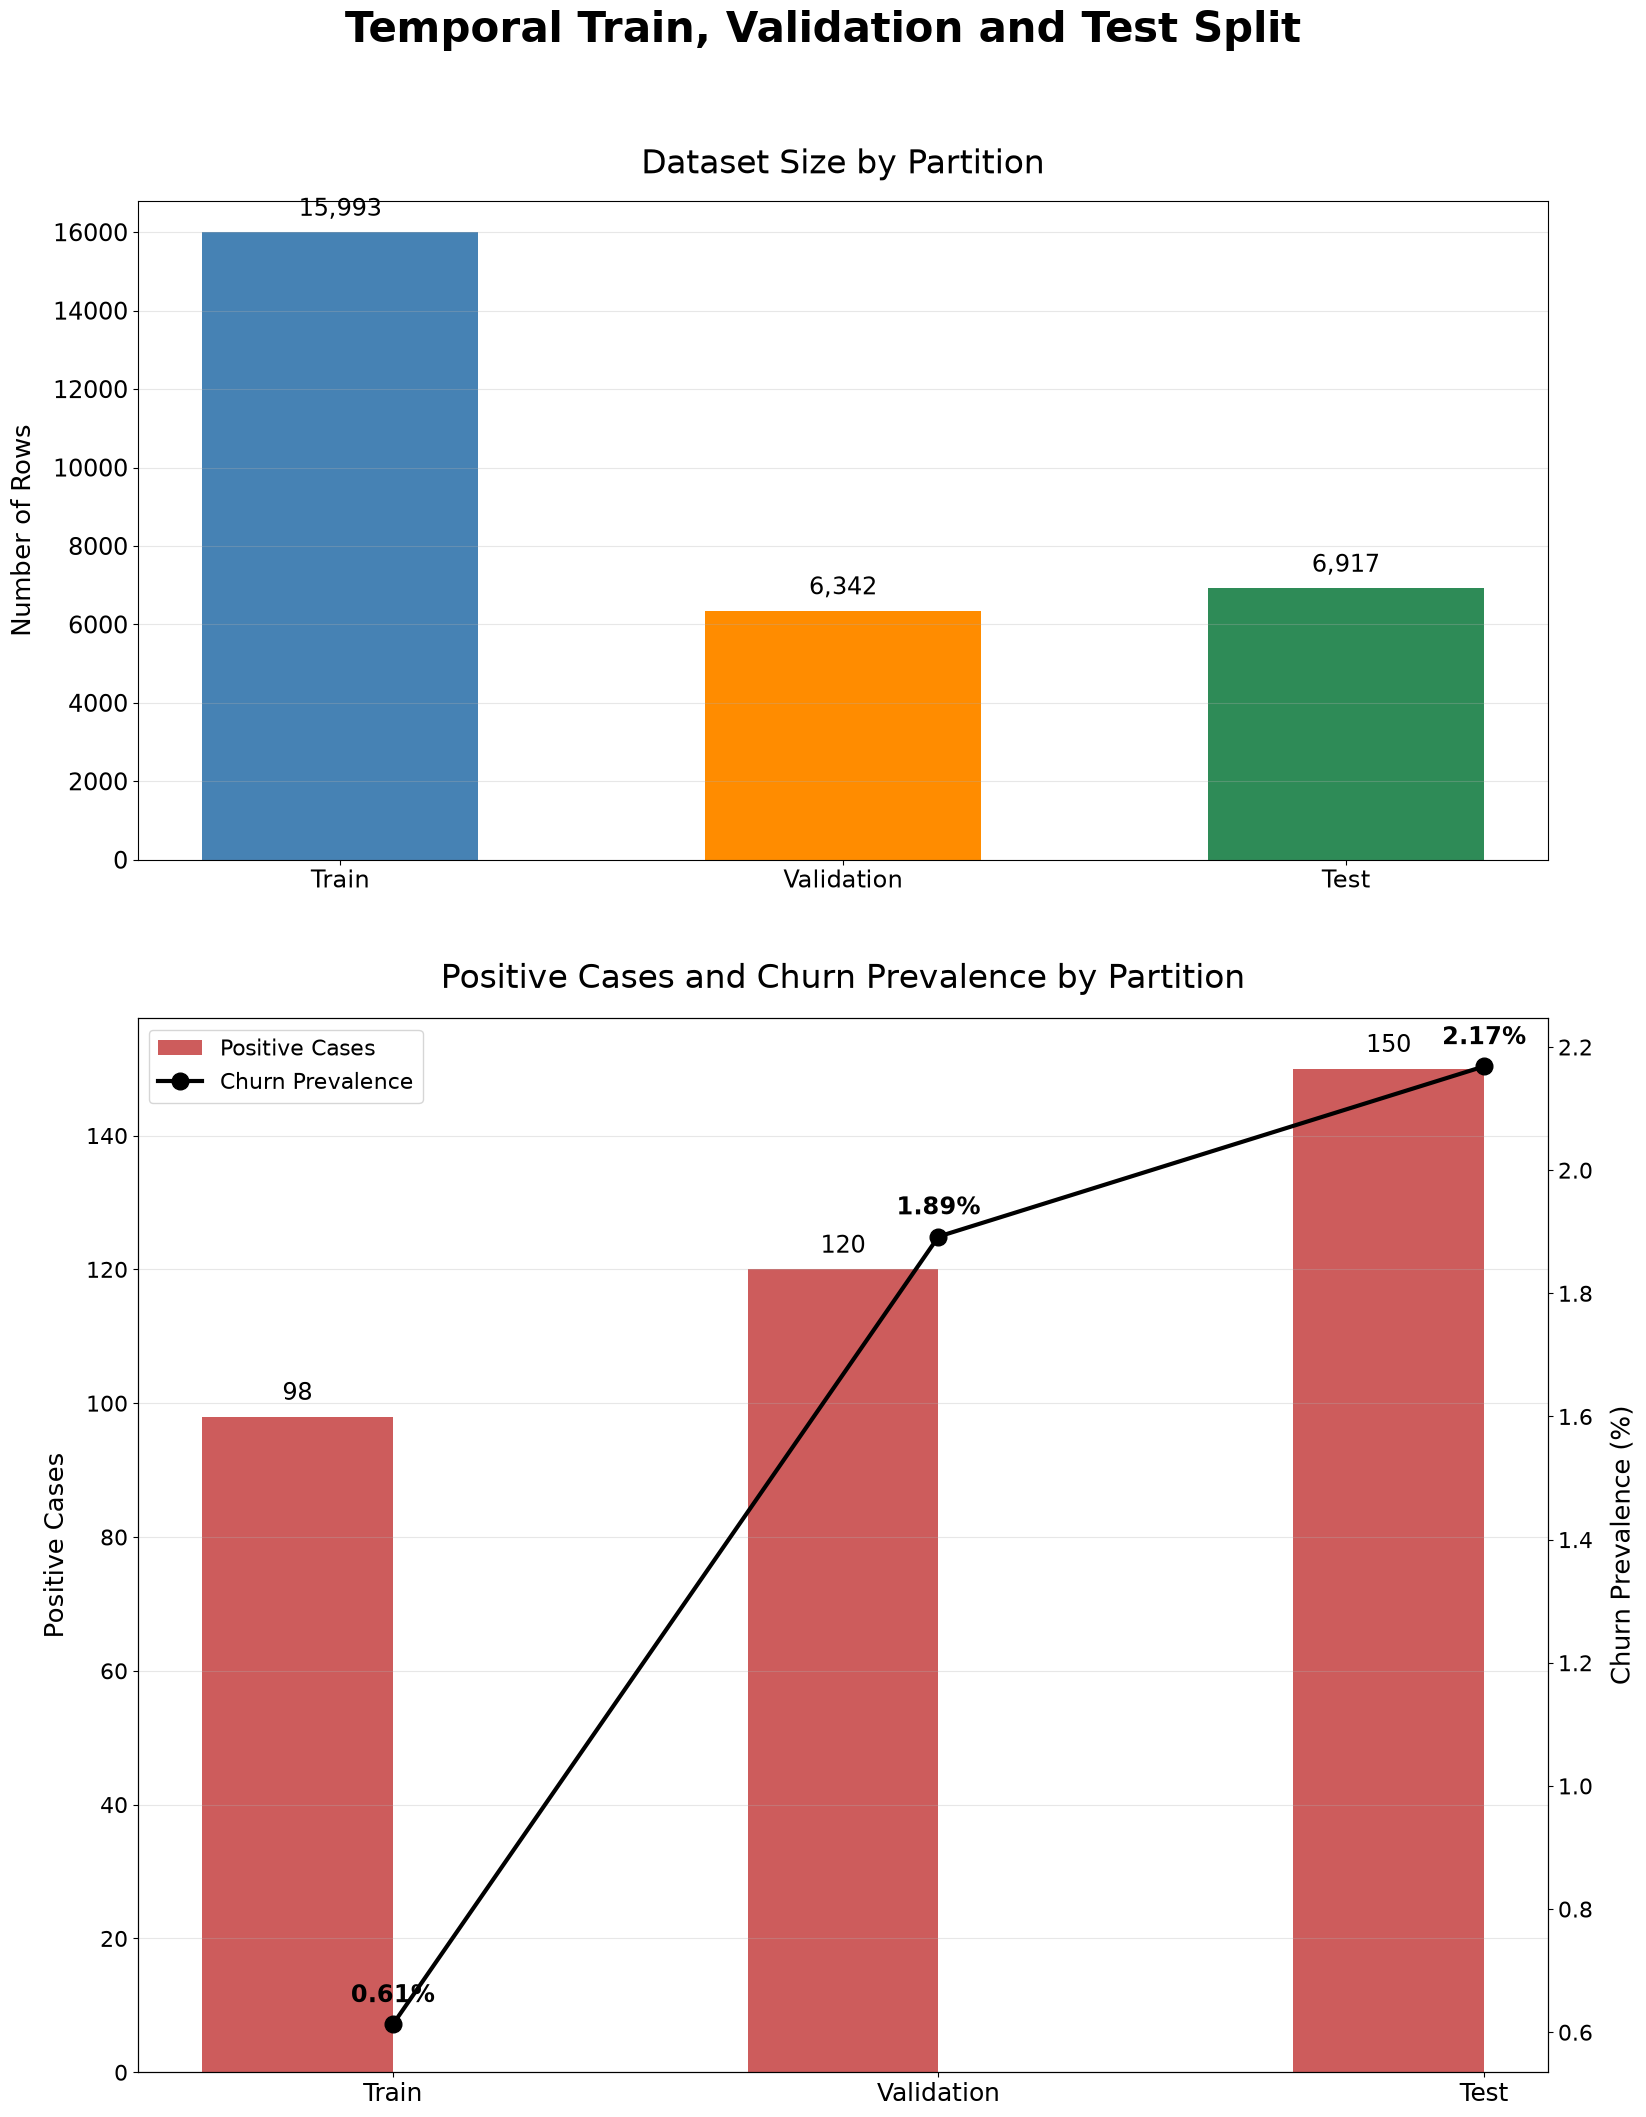

In [27]:
# Summarise the temporal train, validation and test partitions
train_mask = panel["index_date"] <= pd.Timestamp("2025-09-30")

val_mask = panel["index_date"].between(
    pd.Timestamp("2025-10-01"),
    pd.Timestamp("2026-01-31"),
)

test_mask = panel["index_date"].between(
    pd.Timestamp("2026-02-01"),
    pd.Timestamp("2026-05-31"),
)

train = panel.loc[train_mask].copy()
val = panel.loc[val_mask].copy()
test = panel.loc[test_mask].copy()

assert train["index_date"].max() < val["index_date"].min() < test["index_date"].min()


def partition_summary(name, df):
    return {
        "Partition": name,
        "Rows": len(df),
        "Subscribers": df["subscriber_id"].nunique(),
        "Positive Cases": int(df["target_churn_30d"].sum()),
        "Prevalence (%)": df["target_churn_30d"].mean() * 100,
        "Start Date": df["index_date"].min().date(),
        "End Date": df["index_date"].max().date(),
    }


summary = pd.DataFrame([
    partition_summary("Train", train),
    partition_summary("Validation", val),
    partition_summary("Test", test),
])

display(summary)


# Check subscriber overlap between partitions.
train_ids = set(train["subscriber_id"])
val_ids = set(val["subscriber_id"])
test_ids = set(test["subscriber_id"])

print("Subscriber overlap (train / validation):", len(train_ids & val_ids))
print("Subscriber overlap (validation / test):", len(val_ids & test_ids))
print("Subscriber overlap (train / test):", len(train_ids & test_ids))
print("Positive class counts must be inspected before interpreting metrics.")


# Save one large figure summarising the temporal data partitions.
fig, axes = plt.subplots(
    2,
    1,
    figsize=(18, 22),
    gridspec_kw={"height_ratios": [1, 1.6]},
)

# Panel 1: Number of rows in each partition.
axes[0].bar(
    summary["Partition"],
    summary["Rows"],
    color=["steelblue", "darkorange", "seagreen"],
    width=0.55,
)

axes[0].set_title("Dataset Size by Partition", fontsize=24, pad=20)
axes[0].set_ylabel("Number of Rows", fontsize=19, labelpad=12)
axes[0].tick_params(axis="both", labelsize=17)
axes[0].grid(axis="y", alpha=0.3)

for i, value in enumerate(summary["Rows"]):
    axes[0].annotate(
        f"{value:,}",
        (i, value),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=17,
    )


# Panel 2: Positive cases and churn prevalence.
x = np.arange(len(summary))
width = 0.35

bars = axes[1].bar(
    x - width / 2,
    summary["Positive Cases"],
    width,
    label="Positive Cases",
    color="indianred",
)

axes[1].set_ylabel("Positive Cases", fontsize=19, labelpad=12)
axes[1].set_xticks(x)
axes[1].set_xticklabels(summary["Partition"], fontsize=18)
axes[1].tick_params(axis="y", labelsize=16)
axes[1].grid(axis="y", alpha=0.3)

# Use the same categorical positions as the bars to keep the line aligned.
prevalence_ax = axes[1].twinx()

prevalence_ax.plot(
    x,
    summary["Prevalence (%)"],
    color="black",
    marker="o",
    markersize=12,
    linewidth=3,
    label="Churn Prevalence",
)

prevalence_ax.set_ylabel("Churn Prevalence (%)", fontsize=19, labelpad=12)
prevalence_ax.tick_params(axis="y", labelsize=16)

for bar in bars:
    axes[1].annotate(
        f"{bar.get_height():,.0f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=17,
    )

for i, value in enumerate(summary["Prevalence (%)"]):
    prevalence_ax.annotate(
        f"{value:.2f}%",
        (x[i], value),
        xytext=(0, 16),
        textcoords="offset points",
        ha="center",
        fontsize=17,
        fontweight="bold",
    )

axes[1].set_title(
    "Positive Cases and Churn Prevalence by Partition",
    fontsize=24,
    pad=22,
)

handles1, labels1 = axes[1].get_legend_handles_labels()
handles2, labels2 = prevalence_ax.get_legend_handles_labels()

axes[1].legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="upper left",
    fontsize=16,
)

fig.suptitle(
    "Temporal Train, Validation and Test Split",
    fontsize=30,
    fontweight="bold",
    y=0.99,
)

fig.tight_layout(rect=(0.04, 0.03, 0.96, 0.96), h_pad=5)

fig.savefig(
    VISUALISATION_DIR / "temporal_data_partition_summary.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.5,
)

plt.show()
plt.close(fig)

### Encoding and preprocessing

Subscriber IDs, household IDs, index dates and label-window dates are not predictors. Dates are converted into interpretable age/tenure features before modelling. Numeric variables are median-imputed. The categorical variables use the most frequent category and one-hot encoding with safe handling of unseen categories.

In [28]:
from typing import Any, cast

EXCLUDE = {
    "subscriber_id",
    "household_id",
    "index_date",
    "label_window_end",
    "target_churn_30d",
    "subscription_status",
    "subscription_end_date",
    "subscription_start_date",
    "account_creation_date",
    "acquisition_date",
    "cancellation_date",
    "cancellation_reason",
    "cancellation_channel",
    "churn_indicator",
    "reactivation_indicator",
    "reactivation_date",
    "retention_interaction_date",
    "retention_offer",
    "offer_accepted",
    "offer_outcome",
}

# Select predictors and exclude datetime fields that have not been engineered.
train_frame = cast(pd.DataFrame, train)

feature_cols = [
    column
    for column in train_frame.columns
    if column not in EXCLUDE
    and not pd.api.types.is_datetime64_any_dtype(train_frame[column])
]

# Separate predictors and target for each partition.
X_train = train[feature_cols].copy()
y_train = train["target_churn_30d"].astype(int)

X_val = val[feature_cols].copy()
y_val = val["target_churn_30d"].astype(int)

X_test = test[feature_cols].copy()
y_test = test["target_churn_30d"].astype(int)

# Identify numeric and categorical predictors.
num_cols = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

cat_cols = [
    column
    for column in feature_cols
    if column not in num_cols
]

# Ensure categorical missing values are handled consistently.
for frame in [X_train, X_val, X_test]:
    for column in cat_cols:
        frame[column] = frame[column].astype(object)
        frame.loc[frame[column].isna(), column] = np.nan

print(
    "Predictors:", len(feature_cols),
    "| Numeric:", len(num_cols),
    "| Categorical:", len(cat_cols),
)

print("\nSelected predictors:")
print(feature_cols)

print(
    "\nPotentially prohibited fields included:",
    set(feature_cols) & EXCLUDE,
)

assert "subscription_status" not in feature_cols
assert "churn_indicator" not in feature_cols


def make_preprocessor(scale_numeric=False):
    # Impute missing numeric values and optionally standardise features.
    num_steps: list[tuple[str, Any]] = [
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True,
            ),
        )
    ]

    if scale_numeric:
        num_steps.append(
            ("scaler", StandardScaler())
        )

    numeric_pipeline = Pipeline(num_steps)

    # Impute missing categorical values and one-hot encode categories.
    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent"),
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=2,
            ),
        ),
    ])

    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, num_cols),
            ("categorical", categorical_pipeline, cat_cols),
        ],
        remainder="drop",
        verbose_feature_names_out=True,
    )

Predictors: 29 | Numeric: 25 | Categorical: 4

Selected predictors:
['acquisition_channel', 'acquisition_campaign', 'customer_segment', 'province', 'account_age_days', 'subscriber_tenure_days', 'subscription_age_days', 'view_sessions_90d', 'viewing_seconds_90d', 'mean_completion_90d', 'mean_pause_count_90d', 'abandonment_rate_90d', 'days_since_last_viewing', 'engagement_events_90d', 'distinct_event_types_90d', 'search_events_90d', 'content_click_rate_90d', 'scroll_count_90d', 'days_since_last_engagement', 'billing_events_90d', 'amount_charged_90d', 'failed_payment_events_90d', 'refunds_90d', 'refund_amount_90d', 'mean_charge_90d', 'days_since_last_billing', 'view_sessions_observed_90d', 'engagement_events_observed_90d', 'billing_events_observed_90d']

Potentially prohibited fields included: set()


### Baseline and candidate models

XGBoost is the selected model carried forward from the previous assignment and is the primary model for this notebook, consistent with DSA182 Topic 5.
Two predefined XGBoost configurations are compared using validation average precision, with class weighting derived from training labels. If XGBoost is not installed, the cell fails visibly rather than silently changing algorithms.

In [29]:
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier


# Check that the training data contains both target classes
if y_train.nunique() < 2:
    raise ValueError(
        "Training period contains only one target class; "
        "modelling cannot proceed defensibly."
    )


# Calculate the class imbalance ratio for XGBoost
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = float(
    negative_count / max(positive_count, 1)
)

print(
    f"Training positives: {positive_count:,} | "
    f"negatives: {negative_count:,} | "
    f"XGBoost scale_pos_weight: {scale_pos_weight:.3f}"
)


# Define the baseline and candidate models
models = {
    "Dummy prevalence": Pipeline([
        ("prep", make_preprocessor()),
        ("model", DummyClassifier(strategy="prior")),
    ]),

    "XGBoost shallow": Pipeline([
        ("prep", make_preprocessor()),
        (
            "model",
            XGBClassifier(
                n_estimators=250,
                max_depth=2,
                learning_rate=0.04,
                subsample=0.85,
                colsample_bytree=0.85,
                min_child_weight=5,
                reg_lambda=5,
                scale_pos_weight=scale_pos_weight,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=SEED,
                n_jobs=4,
            ),
        ),
    ]),

    "XGBoost regularised": Pipeline([
        ("prep", make_preprocessor()),
        (
            "model",
            XGBClassifier(
                n_estimators=350,
                max_depth=3,
                learning_rate=0.03,
                subsample=0.8,
                colsample_bytree=0.8,
                min_child_weight=10,
                reg_lambda=10,
                scale_pos_weight=scale_pos_weight,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=SEED,
                n_jobs=4,
            ),
        ),
    ]),
}


# Train each model and evaluate its predicted probabilities on the validation set.
candidate_results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    validation_probabilities = model.predict_proba(X_val)[:, 1]

    candidate_results.append({
        "Model": name,
        "Validation Average Precision": average_precision_score(
            y_val,
            validation_probabilities,
        ),
        "Validation ROC-AUC": (
            roc_auc_score(y_val, validation_probabilities)
            if y_val.nunique() == 2
            else np.nan
        ),
        "Validation Brier Score": brier_score_loss(
            y_val,
            validation_probabilities,
        ),
        "Validation Prevalence": y_val.mean(),
    })


# Rank models by average precision, with higher values ranked first.
comparison = (
    pd.DataFrame(candidate_results)
    .sort_values(
        "Validation Average Precision",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(comparison)

Training positives: 98 | negatives: 15,895 | XGBoost scale_pos_weight: 162.194


,Model,Validation Average Precision,Validation ROC-AUC,Validation Brier Score,Validation Prevalence
0,XGBoost regularised,0.023780,0.542595,0.126228,0.018921
1,XGBoost shallow,0.023437,0.543161,0.187198,0.018921
2,Dummy prevalence,0.018921,0.500000,0.018727,0.018921


### Select XGBoost and set a validation threshold

XGBoost is the selected model carried forward from the previous CAP182 assignment. The dummy classifier is retained as a reference benchmark. The two XGBoost configurations are compared, validation average precision selects between those configurations only. Average precision (AP) is the primary ranking metric because the positive class is rare, then compare it with validation prevalence. ROC-AUC measures ranking across thresholds, not accuracy. The classification threshold is chosen on validation data by maximising F1 across candidate thresholds. This is a statistical trade-off, not a financial optimisation. The test set is not used for model or threshold selection.

Selected model: XGBoost regularised
Validation average precision: 0.0238 | prevalence: 0.0189
Selected classification threshold: 0.5572 | validation F1: 0.0484


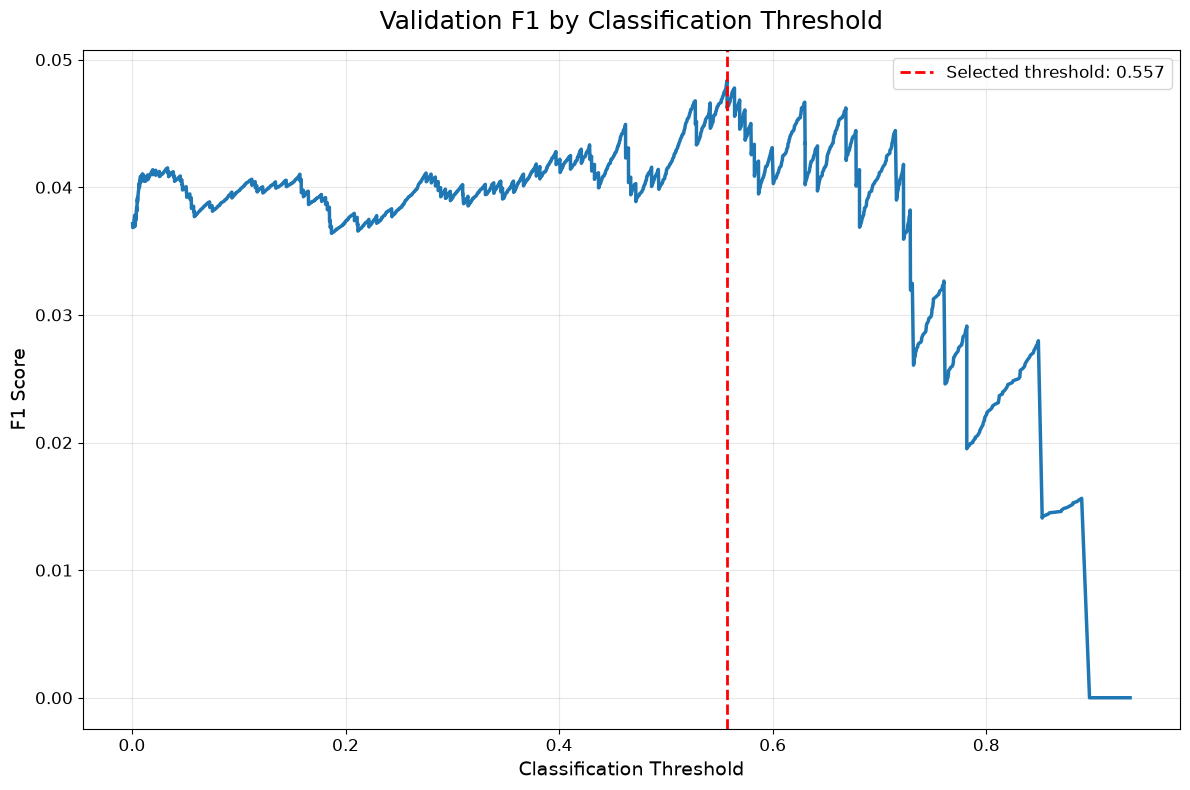

Plot saved to: C:\Users\sltha\Documents\STADIO\CAP182\capstone-project\notebooks\visualisations\validation_f1_by_threshold.png


In [31]:
# XGBoost is the model carried forward from the previous assignment
xgb_candidates = comparison[
    comparison["Model"].str.startswith("XGBoost")
].copy()

if xgb_candidates.empty:
    raise RuntimeError(
        "No XGBoost candidate was evaluated; "
        "do not silently substitute another model."
    )

# Select the XGBoost candidate with the highest validation average precision
selected_name = (
    xgb_candidates
    .sort_values("Validation Average Precision", ascending=False)
    .iloc[0]["Model"]
)

selected_model = models[selected_name]

# Generate churn probabilities for the validation set
val_prob = selected_model.predict_proba(X_val)[:, 1]

# Calculate precision, recall and F1 across classification thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_prob,
)

# precision_recall_curve has one more precision/recall point than thresholds
f1_values = (
    2 * precision[:-1] * recall[:-1]
    / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    if len(thresholds)
    else np.array([])
)

# Select the threshold with the highest validation F1 score
if len(thresholds) and len(f1_values):
    best_idx = int(np.nanargmax(f1_values))

    selected_threshold = float(thresholds[best_idx])
    val_best_f1 = float(f1_values[best_idx])

else:
    selected_threshold = 0.5
    val_best_f1 = np.nan

# Display the selected model and validation results
print("Selected model:", selected_name)

print(
    "Validation average precision:",
    round(average_precision_score(y_val, val_prob), 4),
    "| prevalence:",
    round(y_val.mean(), 4),
)

print(
    "Selected classification threshold:",
    round(selected_threshold, 4),
    "| validation F1:",
    round(val_best_f1, 4),
)

# Plot validation F1 across classification thresholds
fig, ax = plt.subplots(figsize=(12, 8))

ax.plot(thresholds, f1_values, linewidth=2.5)

ax.axvline(
    selected_threshold,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Selected threshold: {selected_threshold:.3f}",
)

ax.set_title(
    "Validation F1 by Classification Threshold",
    fontsize=18,
    pad=15,
)
ax.set_xlabel("Classification Threshold", fontsize=14)
ax.set_ylabel("F1 Score", fontsize=14)
ax.tick_params(axis="both", labelsize=12)
ax.legend(fontsize=12)
ax.grid(alpha=0.3)

plt.tight_layout()

fig.savefig(
    VISUALISATION_DIR / "validation_f1_by_threshold.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.3,
)

plt.show()
plt.close(fig)

print(
    "Plot saved to:",
    (VISUALISATION_DIR / "validation_f1_by_threshold.png").resolve(),
)

### Final test evaluation and diagnostics

The selected model and threshold are now frozen so that the evaluation on the chronological test period starts. AP is reported as average precision (the implementation used here for PR-AUC). Precision and recall describe positive-class predictions at the selected threshold. The confusion matrix uses rows as actual classes and columns as predicted classes.

,ROC_AUC,Average Precision,Precision,Recall,F1 Score,Brier Score,Positive Prevalence,Classification Threshold
Test,0.390357,0.026406,0.01663,0.1,0.028517,0.136489,0.021686,0.557203


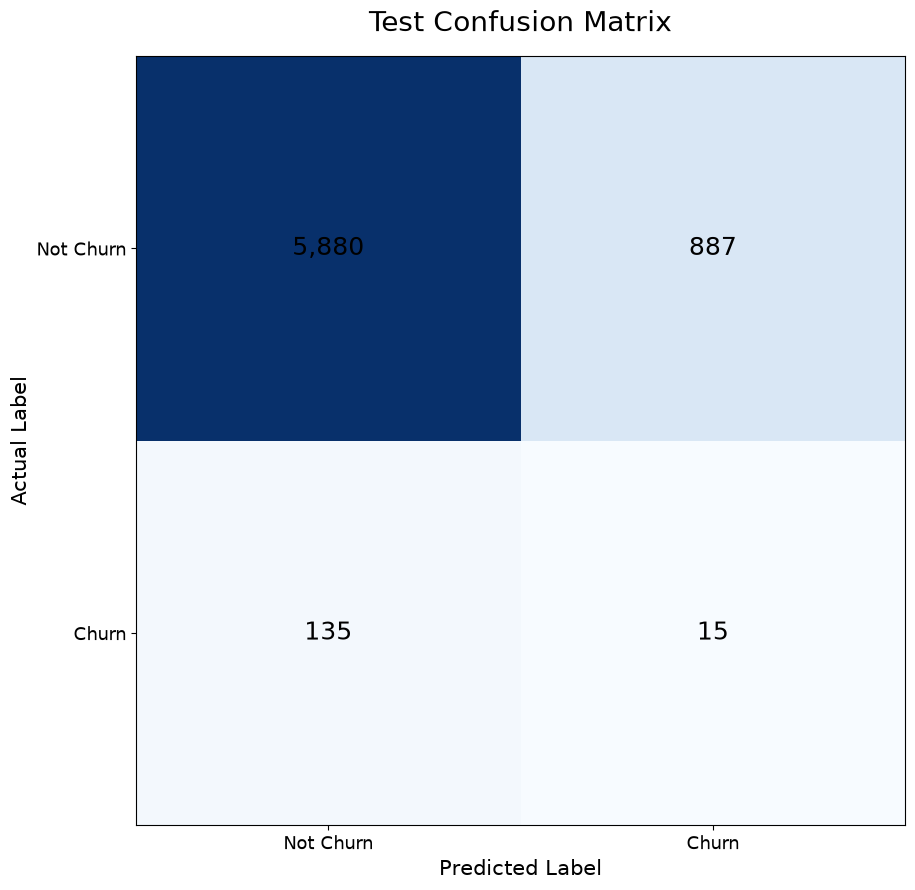

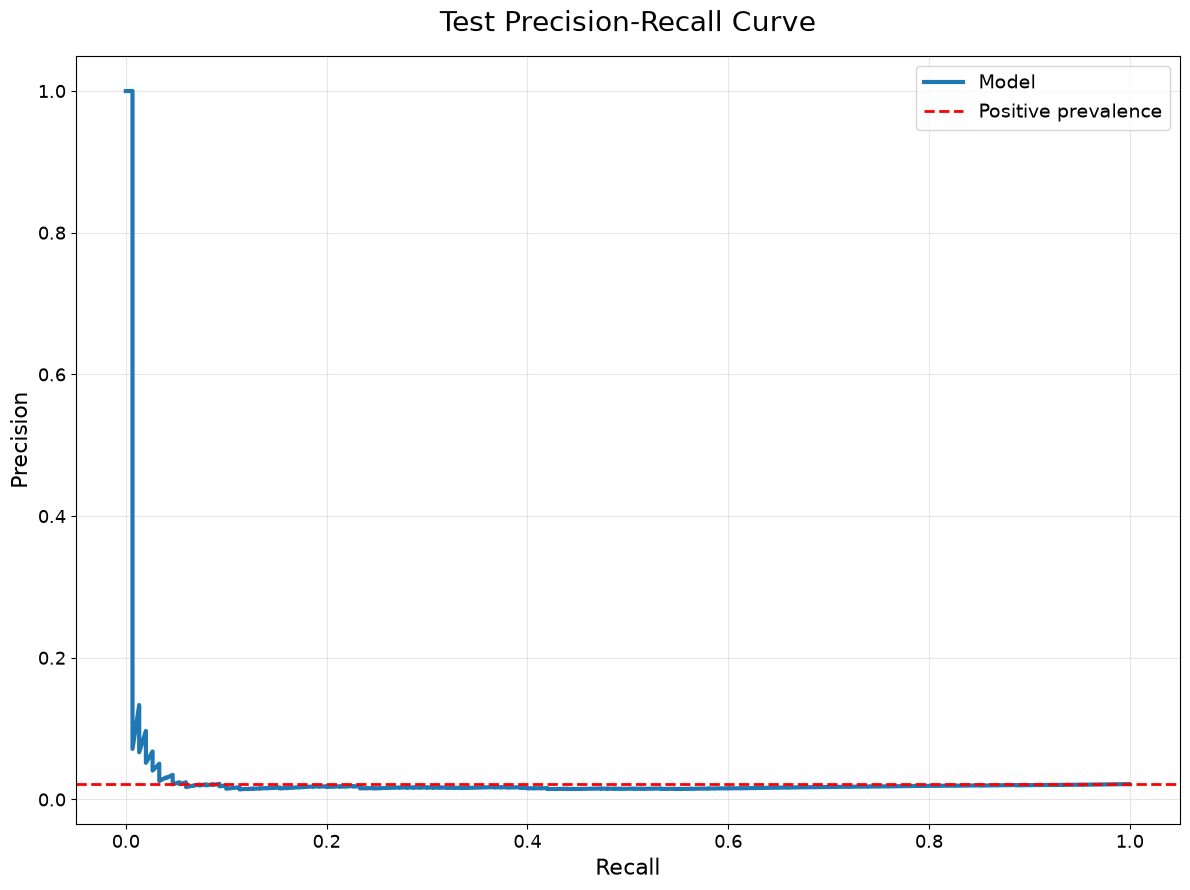

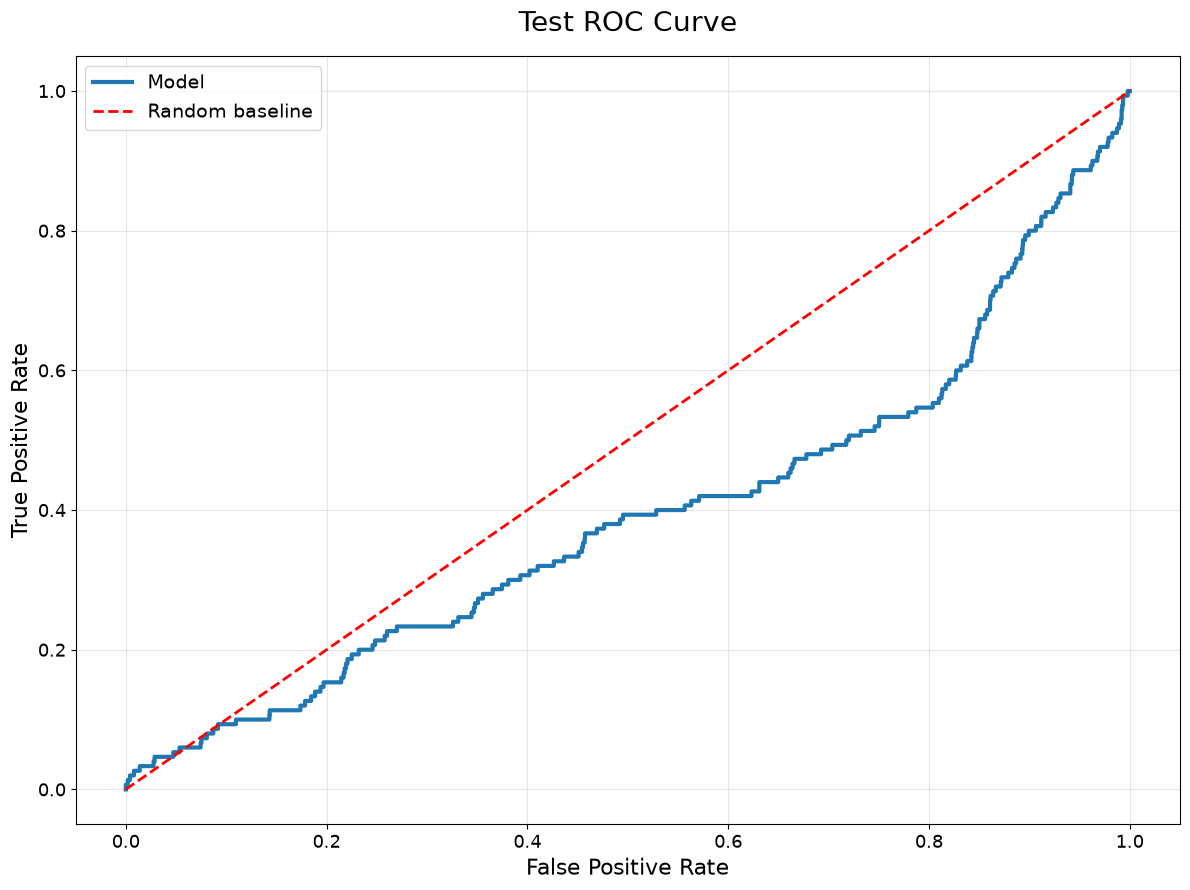

              precision    recall  f1-score   support

   Not Churn       0.98      0.87      0.92      6767
       Churn       0.02      0.10      0.03       150

    accuracy                           0.85      6917
   macro avg       0.50      0.48      0.47      6917
weighted avg       0.96      0.85      0.90      6917

Individual evaluation plots saved to: C:\Users\sltha\Documents\STADIO\CAP182\capstone-project\notebooks\visualisations
Saved: C:\Users\sltha\Documents\STADIO\CAP182\capstone-project\notebooks\visualisations\test_confusion_matrix.png
Saved: C:\Users\sltha\Documents\STADIO\CAP182\capstone-project\notebooks\visualisations\test_precision_recall_curve.png
Saved: C:\Users\sltha\Documents\STADIO\CAP182\capstone-project\notebooks\visualisations\test_roc_curve.png


In [32]:
# Generate predictions for the test set using the selected model and threshold
test_prob = selected_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= selected_threshold).astype(int)


# Calculate evaluation metrics for the test set
def evaluate(y_true, predicted_probabilities, predicted_labels):
    return {
        "ROC_AUC": (
            roc_auc_score(y_true, predicted_probabilities)
            if pd.Series(y_true).nunique() == 2
            else np.nan
        ),
        "Average Precision": average_precision_score(
            y_true, predicted_probabilities
        ),
        "Precision": precision_score(
            y_true, predicted_labels, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predicted_labels, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predicted_labels, zero_division=0
        ),
        "Brier Score": brier_score_loss(
            y_true, predicted_probabilities
        ),
        "Positive Prevalence": float(np.mean(y_true)),
        "Classification Threshold": selected_threshold,
    }


# Display the final test metrics
final_metrics = evaluate(y_test, test_prob, test_pred)
display(pd.DataFrame([final_metrics], index=["Test"]))


# Calculate the confusion matrix
confusion = confusion_matrix(y_test, test_pred, labels=[0, 1])


# Plot 1: Confusion matrix
fig, ax = plt.subplots(figsize=(10, 9))

ax.imshow(confusion, cmap="Blues")

ax.set_title("Test Confusion Matrix", fontsize=20, pad=18)
ax.set_xlabel("Predicted Label", fontsize=15)
ax.set_ylabel("Actual Label", fontsize=15)
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Not Churn", "Churn"], fontsize=13)
ax.set_yticklabels(["Not Churn", "Churn"], fontsize=13)

for (row, column), value in np.ndenumerate(confusion):
    ax.text(
        column,
        row,
        f"{value:,}",
        ha="center",
        va="center",
        fontsize=18,
    )

plt.tight_layout()

fig.savefig(
    VISUALISATION_DIR / "test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.3,
)

plt.show()
plt.close(fig)


# Calculate precision and recall for the test set
pr_precision, pr_recall, _ = precision_recall_curve(y_test, test_prob)


# Plot 2: Precision-recall curve
fig, ax = plt.subplots(figsize=(12, 9))

ax.plot(
    pr_recall,
    pr_precision,
    linewidth=3,
    label="Model",
)

ax.axhline(
    y_test.mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label="Positive prevalence",
)

ax.set_title("Test Precision-Recall Curve", fontsize=20, pad=18)
ax.set_xlabel("Recall", fontsize=16)
ax.set_ylabel("Precision", fontsize=16)
ax.tick_params(axis="both", labelsize=13)
ax.legend(fontsize=14)
ax.grid(alpha=0.3)

plt.tight_layout()

fig.savefig(
    VISUALISATION_DIR / "test_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.3,
)

plt.show()
plt.close(fig)


# Plot 3: ROC curve, if both target classes are present
if y_test.nunique() == 2:
    false_positive_rate, true_positive_rate, _ = roc_curve(
        y_test,
        test_prob,
    )

    fig, ax = plt.subplots(figsize=(12, 9))

    ax.plot(
        false_positive_rate,
        true_positive_rate,
        linewidth=3,
        label="Model",
    )

    ax.plot(
        [0, 1],
        [0, 1],
        color="red",
        linestyle="--",
        linewidth=2,
        label="Random baseline",
    )

    ax.set_title("Test ROC Curve", fontsize=20, pad=18)
    ax.set_xlabel("False Positive Rate", fontsize=16)
    ax.set_ylabel("True Positive Rate", fontsize=16)
    ax.tick_params(axis="both", labelsize=13)
    ax.legend(fontsize=14)
    ax.grid(alpha=0.3)

    plt.tight_layout()

    fig.savefig(
        VISUALISATION_DIR / "test_roc_curve.png",
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.3,
    )

    plt.show()
    plt.close(fig)

else:
    print("ROC curve unavailable: only one test class is present.")


# Display precision, recall and F1 for each target class
print(
    classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=["Not Churn", "Churn"],
        zero_division=0,
    )
)


# Confirm the location of the saved figures
print("Individual evaluation plots saved to:", VISUALISATION_DIR.resolve())

for filename in [
    "test_confusion_matrix.png",
    "test_precision_recall_curve.png",
    "test_roc_curve.png",
]:
    filepath = VISUALISATION_DIR / filename

    if filepath.exists():
        print(f"Saved: {filepath}")

### Diagnostic interpretation

The next stage aims to compare the test AP with test positive prevalence. When AP is only slightly above prevalence then it would indicate limited ranking value. If it is a below-prevalence AP or ROC-AUC near/below 0.5 then it would warrant concern. The next step is to inspect score distributions and labels so that it can be attributed if the algorithm failed or passed.

In [33]:
# Compare test average precision with the positive-class prevalence
test_prevalence = y_test.mean()
test_ap = final_metrics["Average Precision"]

print(
    f"Test prevalence: {test_prevalence:.4f} | "
    f"Test AP: {test_ap:.4f} | "
    f"AP lift over prevalence: {test_ap / max(test_prevalence, 1e-12):.3f}"
)


# Summarise predicted scores for each actual target class
score_diagnostics = (
    pd.DataFrame({
        "Actual Churn": y_test.to_numpy(),
        "Predicted Score": test_prob,
    })
    .groupby("Actual Churn")["Predicted Score"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .rename_axis("Actual Churn")
)

display(score_diagnostics)


# Compare target-class counts across the training, validation and test partitions
print("Target encoding counts by partition:")

target_counts = pd.DataFrame({
    "Train": y_train.value_counts(),
    "Validation": y_val.value_counts(),
    "Test": y_test.value_counts(),
}).fillna(0).astype(int)

target_counts.index = target_counts.index.map({
    0: "Not Churn",
    1: "Churn",
})

display(target_counts)

Test prevalence: 0.0217 | Test AP: 0.0264 | AP lift over prevalence: 1.218


,count,mean,median,std,min,max
Actual Churn,,,,,,
0,6767,0.273565,0.247706,0.222420,0.000611,0.912910
1,150,0.207527,0.084461,0.242234,0.001092,0.930866


Target encoding counts by partition:


,Train,Validation,Test
target_churn_30d,,,
Not Churn,15895,6222,6767
Churn,98,120,150


### Uncertainty and limitations

Repeated monthly records for the same subscriber are related, so treating each row as independent could make confidence intervals too narrow. A subscriber-level bootstrap is used to estimate the uncertainty in test average precision (AP), resampling subscribers while keeping all their test records together. If few subscribers are positive, the interval may be unstable and should be treated as a diagnostic rather than a formal guarantee.

In [34]:
# Prepare test predictions for subscriber-level bootstrap evaluation
rng = np.random.default_rng(SEED)

test_pred_frame = pd.DataFrame({
    "subscriber_id": test["subscriber_id"].to_numpy(),
    "y": y_test.to_numpy(),
    "p": test_prob,
})

subscribers = test_pred_frame["subscriber_id"].unique()

y_array = test_pred_frame["y"].to_numpy()
p_array = test_pred_frame["p"].to_numpy()

# Group row indices by subscriber to preserve subscriber-level clustering
subscriber_rows = {
    subscriber_id: np.flatnonzero(
        test_pred_frame["subscriber_id"].to_numpy() == subscriber_id
    )
    for subscriber_id in subscribers
}

bootstrap_ap = []

# Estimate the 95% confidence interval using subscriber-level resampling
if len(subscribers) >= 10 and test_pred_frame["y"].nunique() == 2:

    for _ in range(100):
        sampled_subscribers = rng.choice(
            subscribers,
            size=len(subscribers),
            replace=True,
        )

        sampled_indices = np.concatenate([
            subscriber_rows[subscriber_id]
            for subscriber_id in sampled_subscribers
        ])

        sampled_targets = y_array[sampled_indices]
        sampled_probabilities = p_array[sampled_indices]

        # Average precision requires both target classes in the sample
        if np.unique(sampled_targets).size == 2:
            bootstrap_ap.append(
                average_precision_score(
                    sampled_targets,
                    sampled_probabilities,
                )
            )

# Display the bootstrap confidence interval
if bootstrap_ap:
    lower_bound, upper_bound = np.quantile(
        bootstrap_ap,
        [0.025, 0.975],
    )

    print(
        "Subscriber-cluster bootstrap AP 95% interval:",
        [round(lower_bound, 4), round(upper_bound, 4)],
        "| Valid replicates:",
        len(bootstrap_ap),
    )

else:
    print(
        "Cluster bootstrap interval not estimated: "
        "insufficient distinct subscribers or target classes."
    )

Subscriber-cluster bootstrap AP 95% interval: [np.float64(0.0161), np.float64(0.0463)] | Valid replicates: 100


### SHAP global and local explanations

SHAP values show how each feature contributes to the model's predictions relative to a reference distribution. The preprocessed features are used to explain the fitted XGBoost model, with one-hot encoded features retaining their original feature names. A reproducible sample is used to keep computation manageable.

  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


SHAP available: True


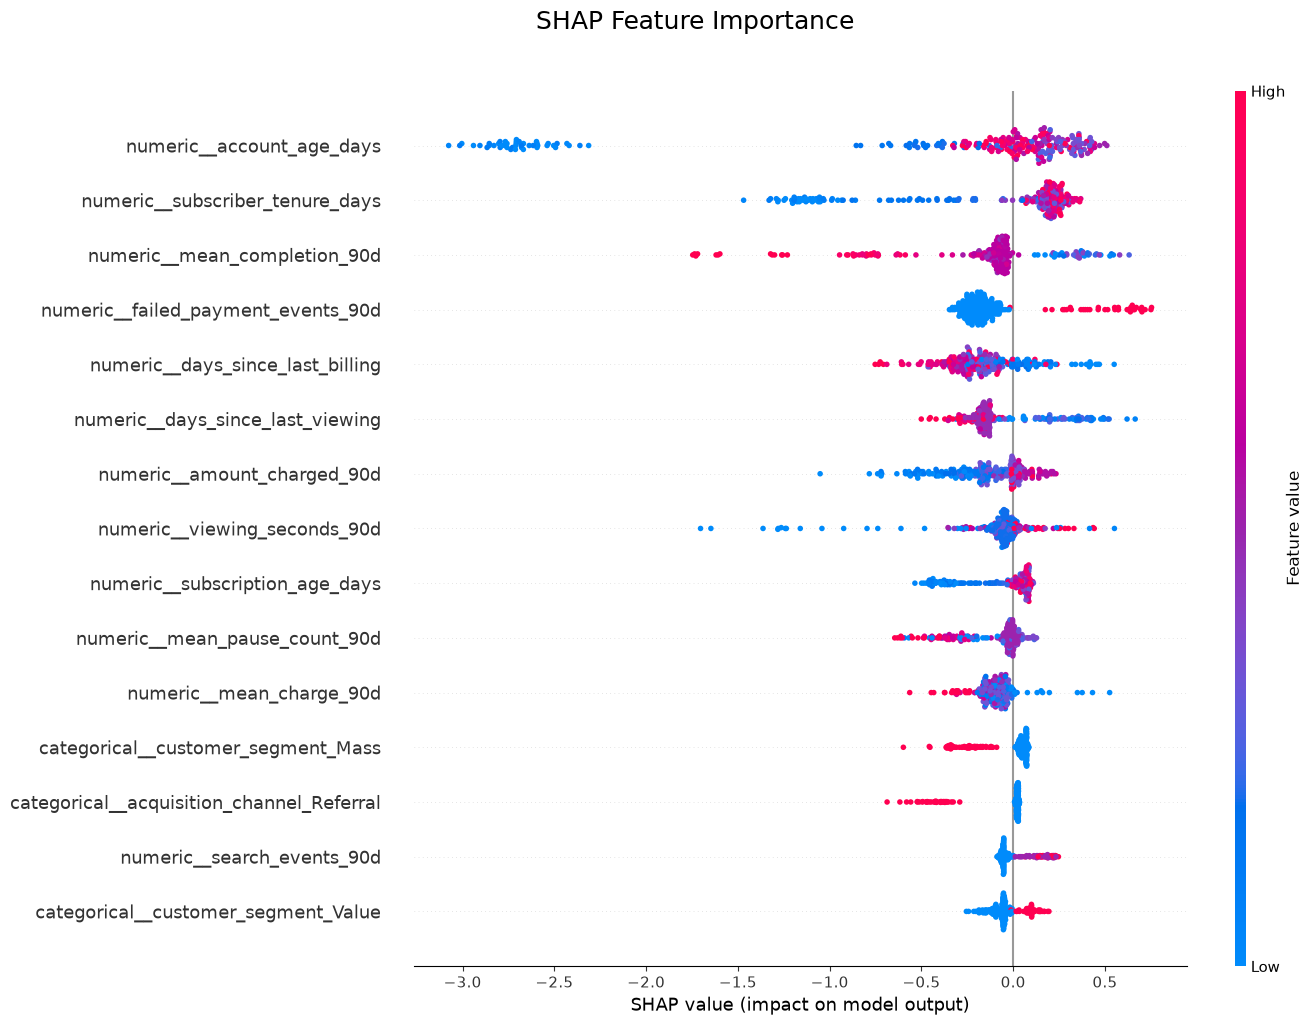

SHAP plot saved to: C:\Users\sltha\Documents\STADIO\CAP182\capstone-project\notebooks\visualisations\shap_feature_importance.png


,feature,mean_abs_shap
0,numeric__account_age_days,0.664473
1,numeric__subscriber_tenure_days,0.397196
2,numeric__mean_completion_90d,0.279887
3,numeric__failed_payment_events_90d,0.239876
4,numeric__days_since_last_billing,0.225637
5,numeric__days_since_last_viewing,0.207333
6,numeric__amount_charged_90d,0.189098
7,numeric__viewing_seconds_90d,0.145438
8,numeric__subscription_age_days,0.133757
9,numeric__mean_pause_count_90d,0.125118


SHAP importance table saved to: C:\Users\sltha\Documents\STADIO\CAP182\capstone-project\notebooks\visualisations\shap_feature_importance.csv


In [35]:
%pip install shap

try:
    import shap
    shap_available = True
except ImportError:
    shap_available = False

print("SHAP available:", shap_available)

shap_values = None
transformed_test = None
transformed_feature_names = None

if shap_available and selected_name in [
    "XGBoost shallow",
    "XGBoost regularised",
]:
    # Retrieve the fitted preprocessing pipeline and estimator
    preprocessor = selected_model.named_steps["prep"]
    fitted_estimator = selected_model.named_steps["model"]

    transformed_test = preprocessor.transform(X_test)
    transformed_feature_names = preprocessor.get_feature_names_out()

    # Convert the transformed test data to a dense array for SHAP
    transformed_dense = (
        transformed_test.toarray()
        if hasattr(transformed_test, "toarray")
        else np.asarray(transformed_test)
    )

    # Select a reproducible sample to limit memory usage
    rng = np.random.default_rng(SEED)

    sample_size = min(250, transformed_dense.shape[0])

    sample_indices = np.sort(
        rng.choice(
            transformed_dense.shape[0],
            size=sample_size,
            replace=False,
        )
    )

    sample_matrix = transformed_dense[sample_indices]

    # Use the explainer appropriate for the selected model
    if selected_name.startswith("XGBoost"):
        explainer = shap.TreeExplainer(fitted_estimator)
        shap_values = explainer.shap_values(sample_matrix)

    else:
        background_size = min(100, transformed_dense.shape[0])

        background_indices = np.sort(
            rng.choice(
                transformed_dense.shape[0],
                size=background_size,
                replace=False,
            )
        )

        background = transformed_dense[background_indices]

        explainer = shap.LinearExplainer(
            fitted_estimator,
            background,
        )

        shap_values = explainer.shap_values(sample_matrix)

    # Handle SHAP output formats that return multiple classes
    if isinstance(shap_values, list):
        shap_values = shap_values[-1]

    if np.asarray(shap_values).ndim == 3:
        shap_values = np.asarray(shap_values)[:, :, -1]

    # Plot the 15 features with the greatest overall SHAP impact
    shap.summary_plot(
        shap_values,
        sample_matrix,
        feature_names=transformed_feature_names,
        show=False,
        max_display=15,
    )

    fig = plt.gcf()
    fig.set_size_inches(14, 10)
    fig.suptitle(
        "SHAP Feature Importance",
        fontsize=18,
        y=1.02,
    )

    plt.tight_layout()

    # Save the SHAP summary plot to the visualisations folder
    shap_plot_path = (
        VISUALISATION_DIR / "shap_feature_importance.png"
    )

    fig.savefig(
        shap_plot_path,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.3,
    )

    plt.show()
    plt.close(fig)

    print("SHAP plot saved to:", shap_plot_path.resolve())

    # Calculate mean absolute SHAP values for global feature importance
    global_shap = (
        pd.DataFrame({
            "feature": transformed_feature_names,
            "mean_abs_shap": np.abs(shap_values).mean(axis=0),
        })
        .sort_values("mean_abs_shap", ascending=False)
        .reset_index(drop=True)
    )

    # Display the 15 most influential features
    display(global_shap.head(15))

    # Save the complete feature importance ranking
    shap_table_path = (
        VISUALISATION_DIR / "shap_feature_importance.csv"
    )

    global_shap.to_csv(shap_table_path, index=False)

    print("SHAP importance table saved to:", shap_table_path.resolve())

else:
    print(
        "SHAP explanation unavailable for the selected model "
        "or because the SHAP dependency is missing; "
        "no explanation is fabricated."
    )

### Individual SHAP explanations

A small sample of actual test observations is selected to show the features with the largest SHAP contributions. Positive values push the prediction toward churn, while negative values push it away from churn. The values are interpreted on the output scale used by the explainer.

In [36]:
# Explain the first sampled test observation 
# and rank its strongest feature contributions
if shap_values is not None:

    local_index = 0

    local_shap = (
        pd.DataFrame({
            "Feature": transformed_feature_names,
            "SHAP Value": shap_values[local_index],
            "Absolute SHAP Value": np.abs(shap_values[local_index]),
        })
        .sort_values("Absolute SHAP Value", ascending=False)
        .head(12)
        .reset_index(drop=True)
    )

    # Display the 12 features with the greatest impact on this prediction
    display(local_shap)

    # Report the observation's actual outcome 
    # and predicted churn probability
    test_row_index = int(sample_indices[local_index])

    print(f"Explained test row index: {test_row_index}")
    print(f"Actual churn outcome: {int(y_test.iloc[test_row_index])}")
    print(f"Predicted churn probability: {test_prob[test_row_index]:.4f}")

else:
    print("Local SHAP explanation unavailable because SHAP values were not calculated.")

,Feature,SHAP Value,Absolute SHAP Value
0,numeric__account_age_days,-2.419538,2.419538
1,numeric__viewing_seconds_90d,-1.263862,1.263862
2,numeric__subscriber_tenure_days,-1.051681,1.051681
3,numeric__amount_charged_90d,-0.633851,0.633851
4,numeric__mean_pause_count_90d,-0.568897,0.568897
5,numeric__refund_amount_90d,-0.556561,0.556561
6,numeric__subscription_age_days,-0.373278,0.373278
7,numeric__mean_completion_90d,-0.331162,0.331162
8,numeric__days_since_last_viewing,-0.243924,0.243924
9,categorical__customer_segment_Value,0.146770,0.146770


Explained test row index: 49
Actual churn outcome: 0
Predicted churn probability: 0.0006


### Probability calibration and practical use

Mean Squared Error (MSE) measures the average squared difference between actual and predicted values; lower values indicate better accuracy, with larger errors penalised more heavily. It is calculated on the untouched test set to assess generalisation, without influencing model selection or tuning. MSE is expressed in squared target units and can be sensitive to extreme values, particularly in small test sets.

In [38]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Evaluate model predictions on the untouched test set
if len(y_test) > 0 and len(test_pred) == len(y_test):

    mse = mean_squared_error(y_test, test_pred)

    print('Test Mean Squared Error (MSE):', round(mse, 4))

    # Additional diagnostic information
    errors = np.asarray(y_test) - np.asarray(test_pred)

    print('Mean prediction error:', round(np.mean(errors), 4))
    print('Largest absolute prediction error:',
          round(np.max(np.abs(errors)), 4))

else:
    print('MSE unavailable: test observations or predictions are invalid.')

print('Large prediction errors contribute disproportionately to MSE.')
print('Prediction errors should be interpreted in the context of '
      'the target variable and its scale.')

Test Mean Squared Error (MSE): 0.1478
Mean prediction error: -0.1087
Largest absolute prediction error: 1
Large prediction errors contribute disproportionately to MSE.
Prediction errors should be interpreted in the context of the target variable and its scale.


## Save reproducibility outputs

Save the executed experiment's metrics, predictions, split summary, feature dictionary and model pipeline. The test labels and scores are saved together so metrics can be independently recomputed. The fitted model is a research artefact only. The performance and calibration evidence must be sufficient before practical use.

In [41]:
from pathlib import Path
import json
import platform
import joblib

# Create reproducibility output directory
OUTPUT_DIR = Path.cwd().resolve() / "stadiochoice_churn_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Reproducibility outputs directory: {OUTPUT_DIR}")

# Save test predictions for auditing
pred_out = test[
    ["subscriber_id", "index_date", "target_churn_30d"]
].copy()

pred_out["predicted_probability"] = test_prob
pred_out["predicted_label"] = test_pred
pred_out["threshold"] = selected_threshold

pred_out.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False,
)

# Save test metrics and validation model comparison
pd.DataFrame([final_metrics]).to_csv(
    OUTPUT_DIR / "test_metrics.csv",
    index=False,
)

comparison.to_csv(
    OUTPUT_DIR / "validation_model_comparison.csv",
    index=False,
)

# Save dataset partition summary
split_summary = pd.DataFrame([
    partition_summary("train", train),
    partition_summary("validation", val),
    partition_summary("test", test),
])

split_summary.to_csv(
    OUTPUT_DIR / "split_summary.csv",
    index=False,
)

# Document feature definitions and time references
feature_dictionary = pd.DataFrame(
    [
        (
            "account_age_days",
            "Index date minus account creation date",
            "Account table",
            "days",
            "At index date",
        ),
        (
            "subscriber_tenure_days",
            "Index date minus acquisition date",
            "Account table",
            "days",
            "At index date",
        ),
        (
            "subscription_age_days",
            "Index date minus subscription start date",
            "Subscription table",
            "days",
            "At index date",
        ),
        (
            "view_sessions_90d",
            "Distinct session IDs in previous 90 days",
            "Viewing table",
            "sessions",
            "Lookback: (index−90d, index]",
        ),
        (
            "viewing_seconds_90d",
            "Sum of viewing duration in previous 90 days",
            "Viewing table",
            "seconds",
            "Lookback: (index−90d, index]",
        ),
        (
            "mean_completion_90d",
            "Mean completion rate in previous 90 days",
            "Viewing table",
            "proportion",
            "Lookback: (index−90d, index]",
        ),
        (
            "days_since_last_viewing",
            "Days from index date to last viewing",
            "Viewing table",
            "days",
            "At index date",
        ),
        (
            "engagement_events_90d",
            "Number of engagement event rows in previous 90 days",
            "Engagement table",
            "events",
            "Lookback: (index−90d, index]",
        ),
        (
            "search_events_90d",
            "Number of Search events in previous 90 days",
            "Engagement table",
            "events",
            "Lookback: (index−90d, index]",
        ),
        (
            "failed_payment_events_90d",
            "Sum of payment failure indicators in previous 90 days",
            "Billing table",
            "events",
            "Lookback: (index−90d, index]",
        ),
        (
            "amount_charged_90d",
            "Sum of amount charged in previous 90 days",
            "Billing table",
            "ZAR",
            "Lookback: (index−90d, index]",
        ),
        (
            "days_since_last_billing",
            "Days from index date to last billing event",
            "Billing table",
            "days",
            "At index date",
        ),
    ],
    columns=[
        "feature",
        "calculation",
        "source",
        "unit",
        "time_reference",
    ],
)

feature_dictionary.to_csv(
    OUTPUT_DIR / "feature_dictionary.csv",
    index=False,
)

# Save the selected model pipeline
joblib.dump(
    selected_model,
    OUTPUT_DIR / "selected_model_pipeline.joblib",
)

# Save experiment configuration and results
metadata = {
    "seed": SEED,
    "prediction_horizon_days": HORIZON_DAYS,
    "lookback_days": LOOKBACK_DAYS,
    "selected_model": selected_name,
    "selected_threshold": selected_threshold,
    "features": feature_cols,
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "test_metrics": final_metrics,
    "index_dates": [
        str(date.date()) for date in INDEX_DATES
    ],
}

metadata_path = OUTPUT_DIR / "experiment_metadata.json"
metadata_path.write_text(
    json.dumps(metadata, indent=2, default=str),
    encoding="utf-8",
)

# List saved outputs
print("\nSaved files:")

for file_path in sorted(OUTPUT_DIR.iterdir()):
    print(f"- {file_path.name}")

Reproducibility outputs directory: C:\Users\sltha\Documents\STADIO\CAP182\capstone-project\notebooks\stadiochoice_churn_outputs

Saved files:
- experiment_metadata.json
- feature_dictionary.csv
- selected_model_pipeline.joblib
- split_summary.csv
- test_metrics.csv
- test_predictions.csv
- validation_model_comparison.csv
